In [34]:
import os
import csv
import pandas as pd

from PIL import Image
from concurrent.futures import ThreadPoolExecutor

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns

import torch

from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models
from transformers import AutoTokenizer, DistilBertModel
import torch.nn as nn

import json
import time
import numpy as np
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
from torch.optim import AdamW

from sklearn.utils.class_weight import compute_class_weight

### Load the CSV file and check for the number of products and images.

In [26]:
styles_df = pd.read_csv("myntradataset/styles.csv", on_bad_lines="skip")

image_dir = "myntradataset/images"

image_files = [
    f
    for f in os.listdir(image_dir)
    if os.path.isfile(os.path.join(image_dir, f))
]

print(f"Total products in styles.csv: {len(styles_df)}")
print(f"Total image files in folder: {len(image_files)}")


Total products in styles.csv: 44424
Total image files in folder: 44441


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


## Check for damages images

In [5]:
image_dir = "myntradataset/images"

def verify_image(filename):
    file_path = os.path.join(image_dir, filename)
    if not os.path.isfile(file_path):
        return None
    
    try:
        with Image.open(file_path) as img:
            img.load() 
        return None
    except Exception as e:
        return (filename, str(e))

image_files = os.listdir(image_dir)

print(f"Checking {len(image_files)} images...")
with ThreadPoolExecutor() as executor:
    results = list(executor.map(verify_image, image_files))

damaged_images = [res for res in results if res is not None]

print("\n=== Image Integrity Audit Report ===")
print(f"Total images scanned: {len(image_files)}")
print(f"Total damaged/unopenable images: {len(damaged_images)}")

if damaged_images:
    print("\nSample damaged files:")
    for file, error in damaged_images[:10]:
        print(f"- {file}: {error}")
    if len(damaged_images) > 10:
        print(f"... and {len(damaged_images) - 10} more.")

Checking 44441 images...

=== Image Integrity Audit Report ===
Total images scanned: 44441
Total damaged/unopenable images: 0


## Check for corrupted CSV rows, duplicate products, missing IDs. Remove them

In [8]:
file_path = "myntradataset/styles.csv"

valid_rows = []
malformed_line_count = 0

with open(file_path, "r", encoding="utf-8", errors="replace") as f:
    reader = csv.reader(f)
    header = next(reader)
    expected_cols = len(header)

    for row in reader:
        if len(row) == expected_cols:
            valid_rows.append(row)
        else:
            malformed_line_count += 1

styles_df = pd.DataFrame(valid_rows, columns=header)

missing_ids_mask = styles_df["id"].isna() | (styles_df["id"].str.strip() == "")
missing_id_count = missing_ids_mask.sum()
df_filtered = styles_df[~missing_ids_mask].copy()

category_cols = ["gender", "masterCategory", "subCategory", "articleType"]
cat_cols_present = [col for col in category_cols if col in df_filtered.columns]

missing_cat_mask = df_filtered[cat_cols_present].isna().any(axis=1) | (
    df_filtered[cat_cols_present] == ""
).any(axis=1)
missing_cat_count = missing_cat_mask.sum()
df_filtered = df_filtered[~missing_cat_mask].copy()

duplicate_ids_mask = df_filtered.duplicated(subset=["id"], keep="first")
duplicate_id_count = duplicate_ids_mask.sum()
styles_clean_df = df_filtered[~duplicate_ids_mask].copy()

total_removed = (
    malformed_line_count
    + missing_id_count
    + missing_cat_count
    + duplicate_id_count
)

print("=== CSV Cleaning & Integrity Report ===")
print(f"Malformed rows (column mismatch) : {malformed_line_count}")
print(f"Missing Product IDs             : {missing_id_count}")
print(
    f"Missing Category Labels         : {missing_cat_count} (Checked: {', '.join(cat_cols_present)})"
)
print(f"Duplicate Product IDs           : {duplicate_id_count}")
print("---------------------------------------")
print(f"Total rows removed              : {total_removed}")
print(f"Final clean dataset row count   : {len(styles_clean_df)}")

=== CSV Cleaning & Integrity Report ===
Malformed rows (column mismatch) : 22
Missing Product IDs             : 0
Missing Category Labels         : 0 (Checked: gender, masterCategory, subCategory, articleType)
Duplicate Product IDs           : 0
---------------------------------------
Total rows removed              : 22
Final clean dataset row count   : 44424


## Match the rows to image by ID. Give the remaining count.

In [9]:
image_dir = "myntradataset/images"

if "styles_clean_df" in locals():
    df_to_check = styles_clean_df.copy()
else:
    df_to_check = pd.read_csv("myntradataset/styles.csv", on_bad_lines="skip")


def verify_product_image(product_id):
    pid_str = str(product_id).split(".")[0].strip()

    candidates = [
        f"{pid_str}.jpg",
        f"{pid_str}.png",
        f"{pid_str}.jpeg",
        pid_str,
    ]

    found_file = False
    for cand in candidates:
        path = os.path.join(image_dir, cand)
        if os.path.isfile(path):
            found_file = True
            try:
                with Image.open(path) as img:
                    img.load() 
                return (product_id, path, "valid")
            except Exception:
                return (product_id, None, "damaged")

    if not found_file:
        return (product_id, None, "missing")


product_ids = df_to_check["id"].dropna().unique()

print(f"Matching {len(product_ids)} products to images in {image_dir}...")

with ThreadPoolExecutor() as executor:
    results = list(executor.map(verify_product_image, product_ids))

status_df = pd.DataFrame(results, columns=["id", "image_path", "image_status"])

status_counts = status_df["image_status"].value_counts()
valid_count = status_counts.get("valid", 0)
missing_count = status_counts.get("missing", 0)
damaged_count = status_counts.get("damaged", 0)

valid_status_df = status_df[status_df["image_status"] == "valid"][
    ["id", "image_path"]
]
final_dataset = df_to_check.merge(valid_status_df, on="id", how="inner")

print("\n=== Product-Image Matching Report ===")
print(f"Total products checked         : {len(df_to_check)}")
print(f"Products with missing images   : {missing_count}")
print(f"Products with damaged images   : {damaged_count}")
print("---------------------------------------")
print(f"Final valid products remaining : {len(final_dataset)}")

Matching 44424 products to images in myntradataset/images...

=== Product-Image Matching Report ===
Total products checked         : 44424
Products with missing images   : 5
Products with damaged images   : 0
---------------------------------------
Final valid products remaining : 44419


## Keep the minimum 300 product categories, give the category list with the count of the products in each of them

=== SubCategories with >= 300 Products ===
subCategory
Topwear                     15398
Shoes                        7343
Bags                         3055
Bottomwear                   2693
Watches                      2542
Innerwear                    1808
Jewellery                    1079
Eyewear                      1073
Fragrance                    1011
Sandal                        963
Wallets                       933
Flip Flops                    913
Belts                         811
Socks                         698
Lips                          527
Dress                         478
Loungewear and Nightwear      470
Saree                         427
Nails                         329
Makeup                        307
Name: count, dtype: int64

Total subcategories retained : 20
Total products retained      : 42858


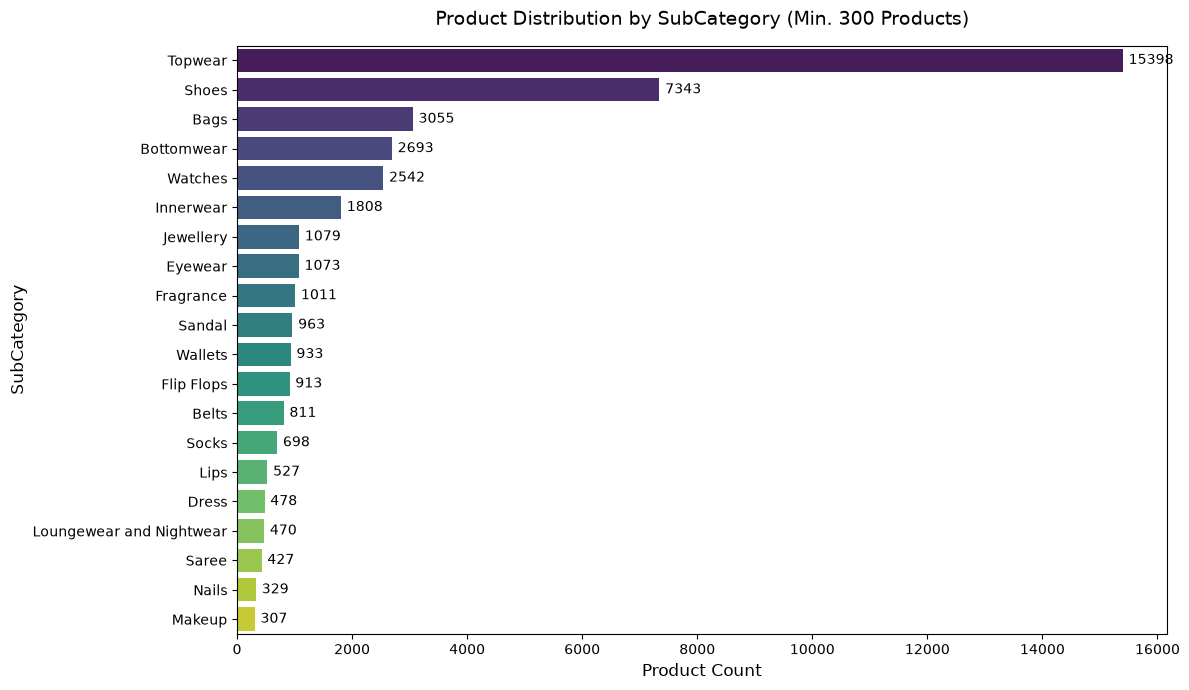

Cleaned dataset successfully saved to: myntradataset/styles_cleaned.csv


In [11]:
if "final_dataset" in locals():
    df_to_process = final_dataset.copy()
elif "styles_clean_df" in locals():
    df_to_process = styles_clean_df.copy()
else:
    df_to_process = pd.read_csv("myntradataset/styles.csv", on_bad_lines="skip")

subcat_counts = df_to_process["subCategory"].value_counts()

THRESHOLD = 300
valid_subcategories = subcat_counts[subcat_counts >= THRESHOLD].index

styles_final_filtered = df_to_process[
    df_to_process["subCategory"].isin(valid_subcategories)
].copy()
filtered_counts = styles_final_filtered["subCategory"].value_counts()

print(f"=== SubCategories with >= {THRESHOLD} Products ===")
print(filtered_counts)
print("\n" + "=" * 40)
print(f"Total subcategories retained : {len(filtered_counts)}")
print(f"Total products retained      : {len(styles_final_filtered)}")

plt.figure(figsize=(12, 7))
sns.barplot(
    x=filtered_counts.values,
    y=filtered_counts.index,
    palette="viridis",
    hue=filtered_counts.index,
    legend=False,
)

plt.xlabel("Product Count", fontsize=12)
plt.ylabel("SubCategory", fontsize=12)
plt.title(
    f"Product Distribution by SubCategory (Min. {THRESHOLD} Products)",
    fontsize=14,
    pad=15,
)

for index, value in enumerate(filtered_counts.values):
    plt.text(value + 100, index, str(value), va="center", fontsize=10)

plt.tight_layout()
plt.show()

output_dir = "myntradataset"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, "styles_cleaned.csv")

styles_final_filtered.to_csv(output_path, index=False)
print(f"Cleaned dataset successfully saved to: {output_path}")

## For each category, show some products, with photo, name, color to check the mapping correctness

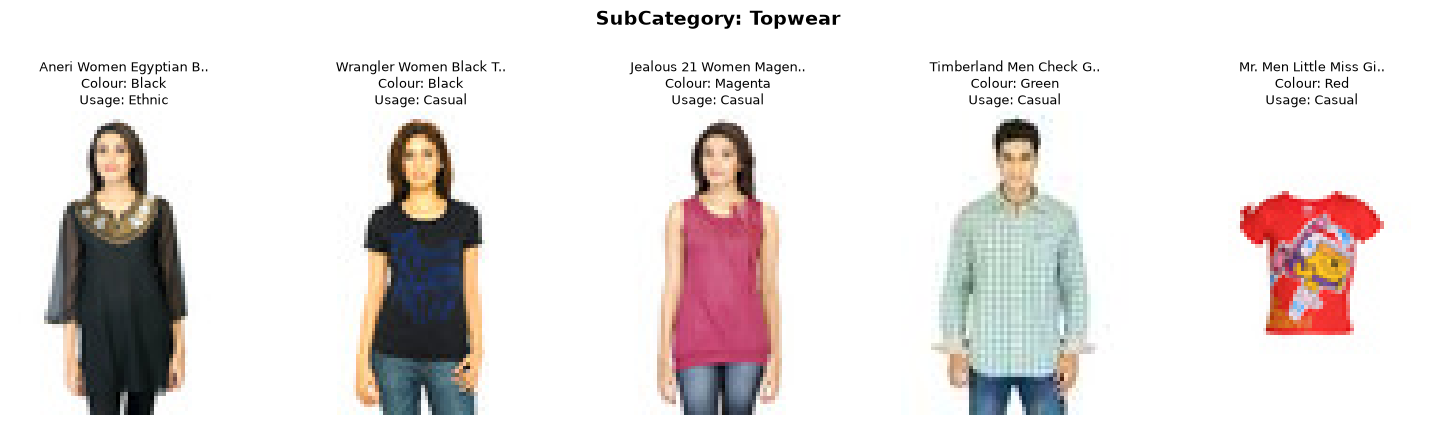

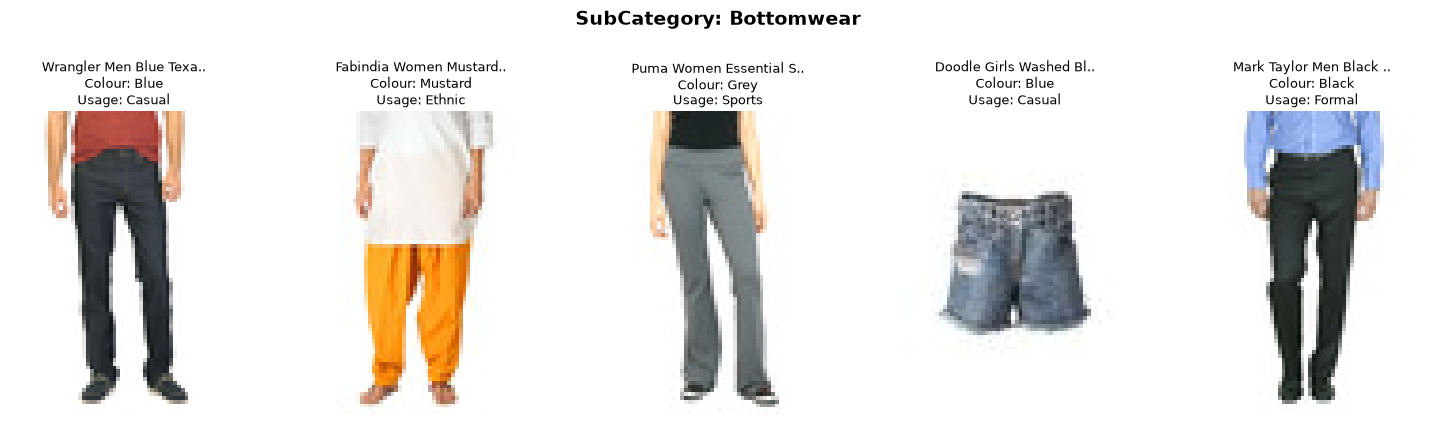

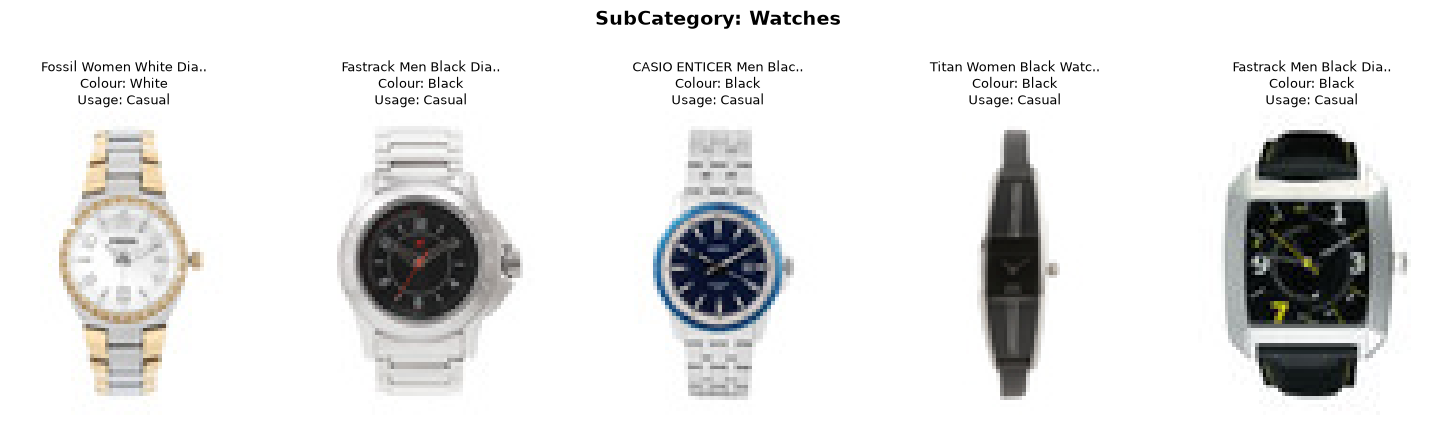

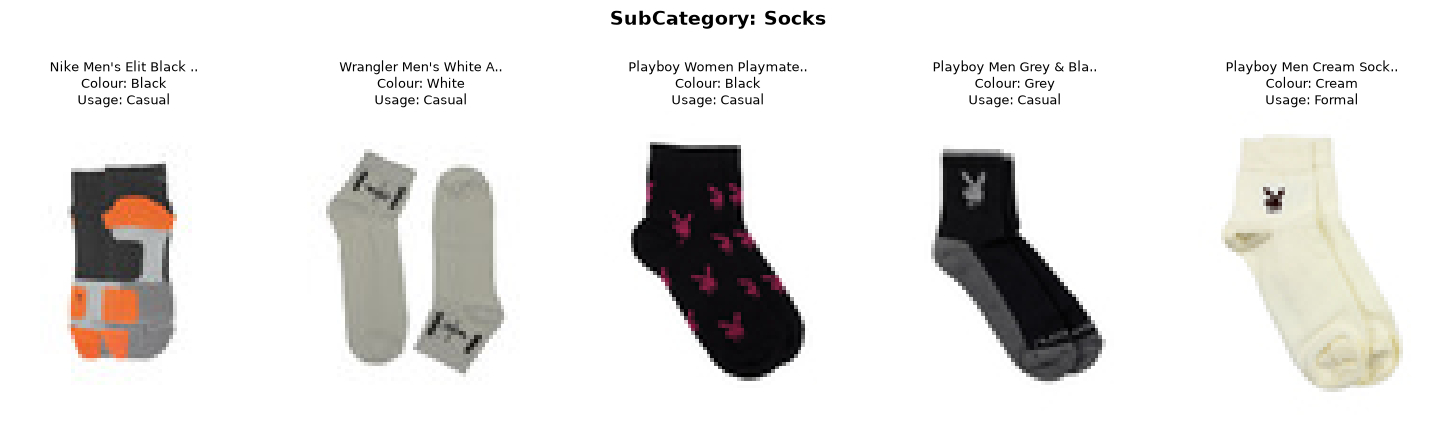

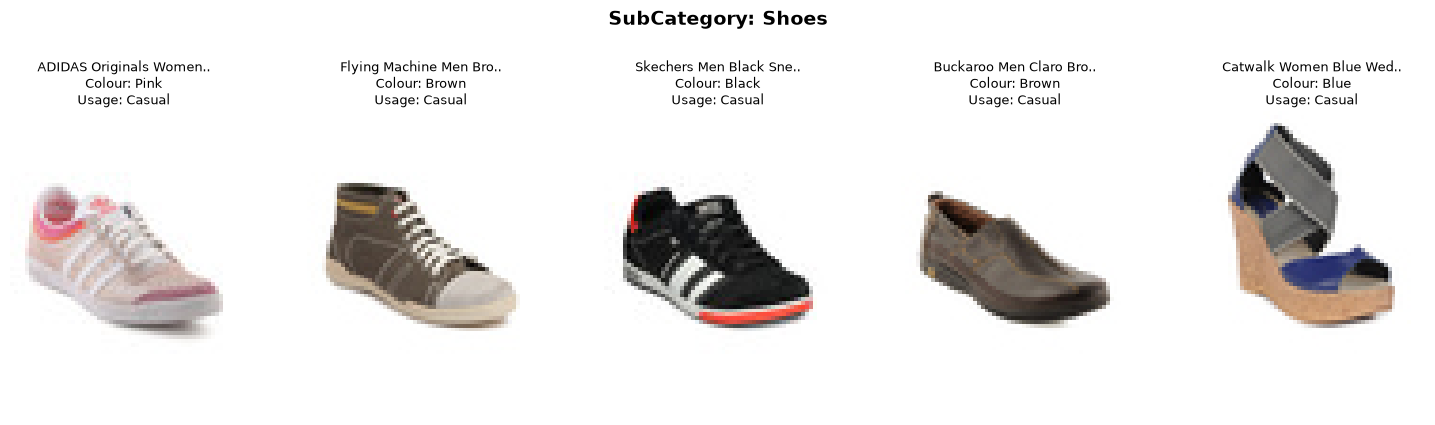

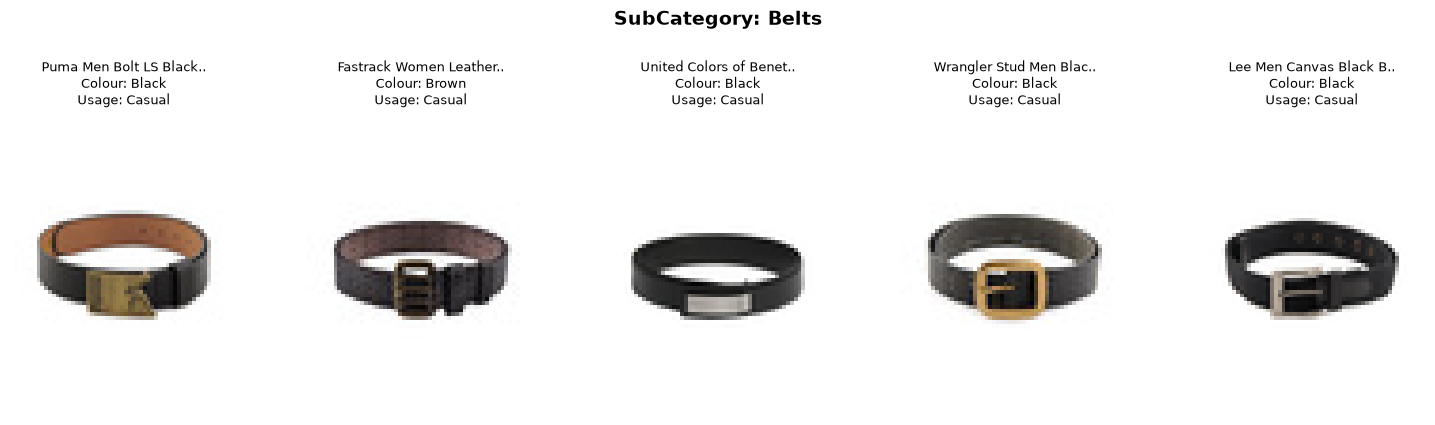

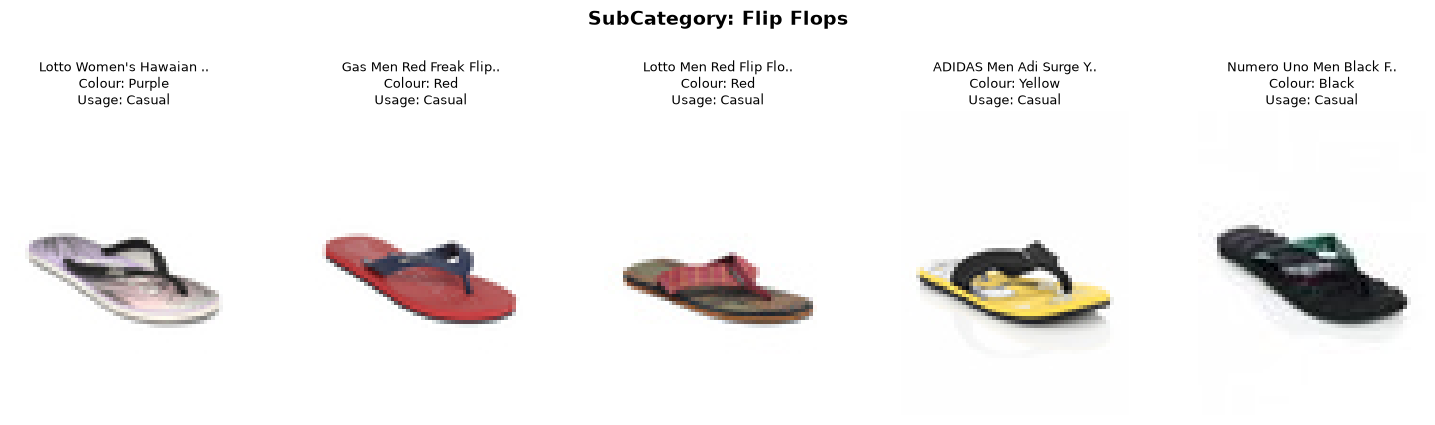

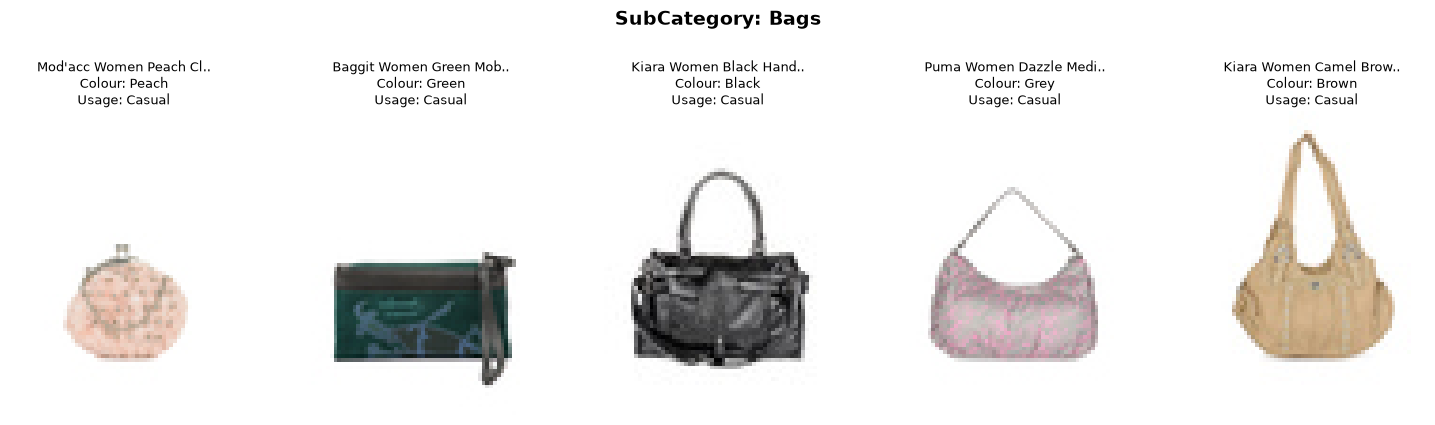

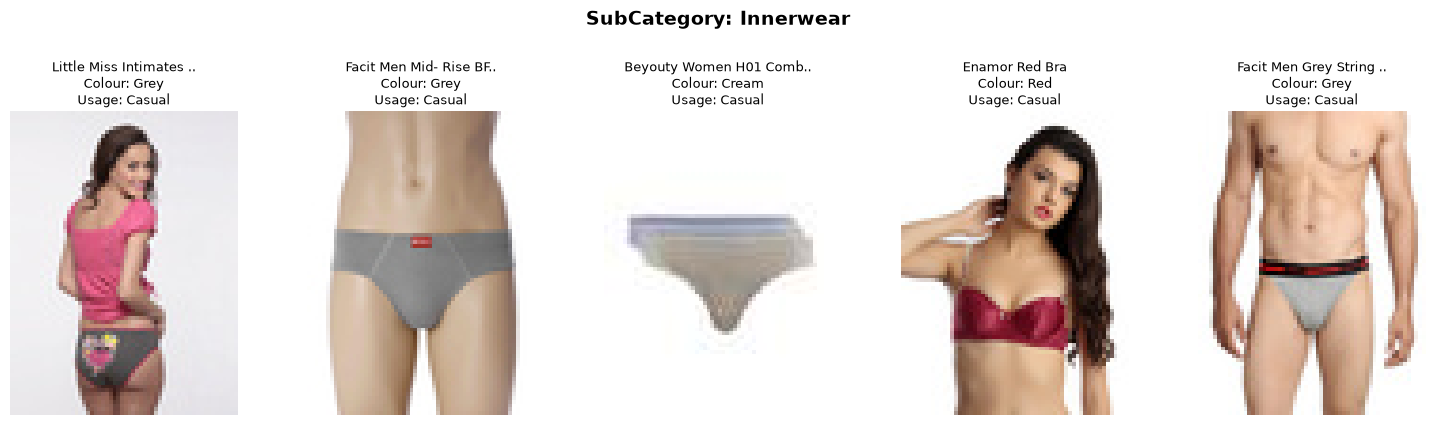

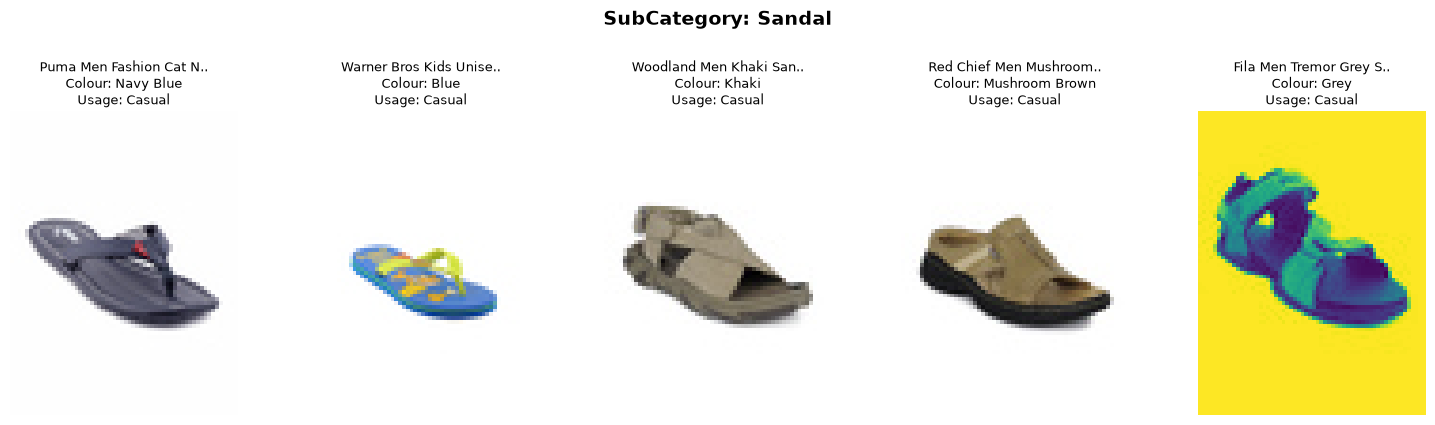

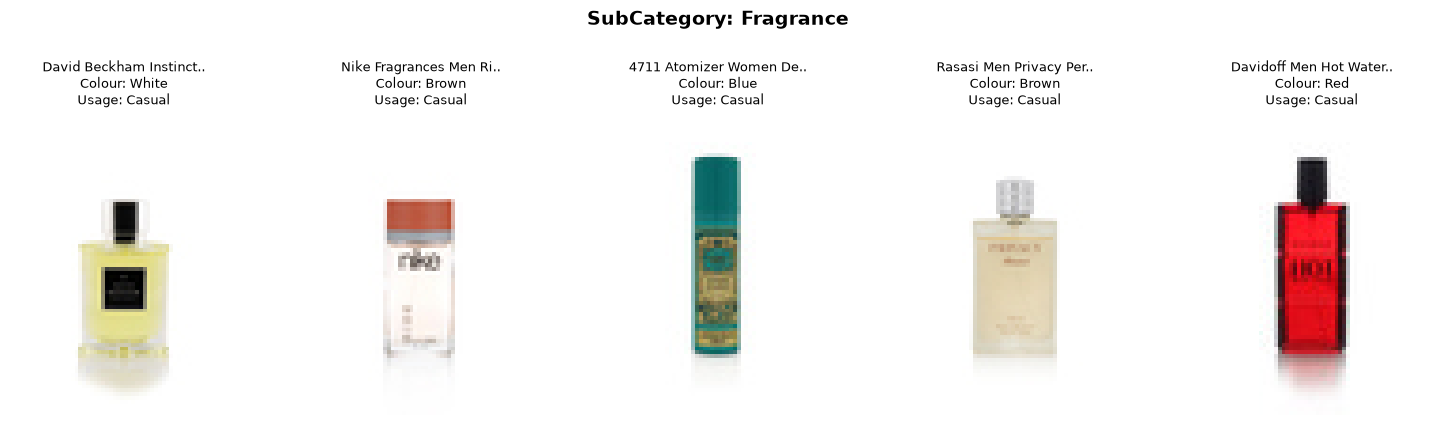

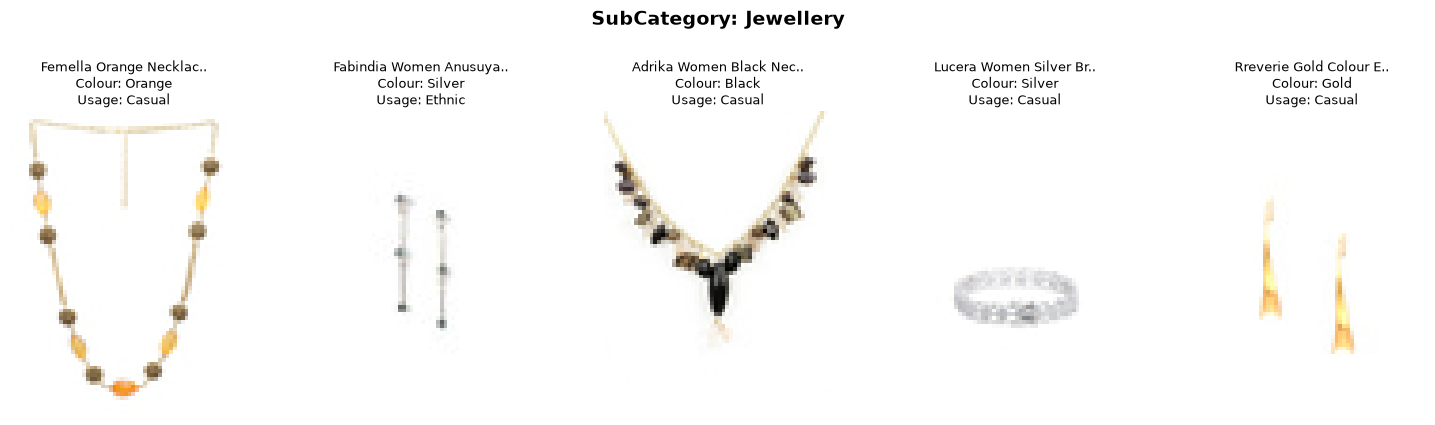

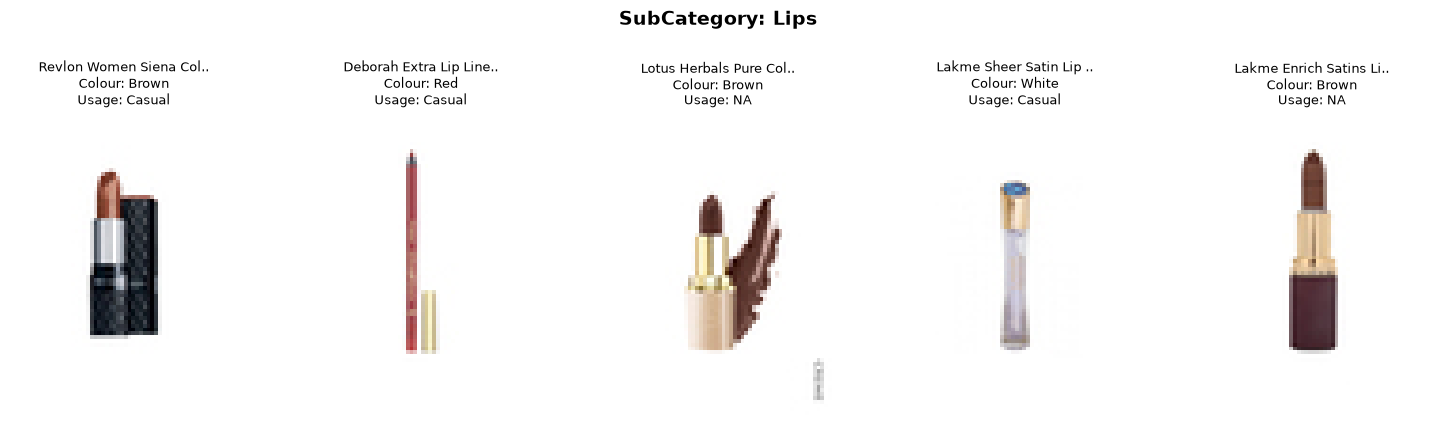

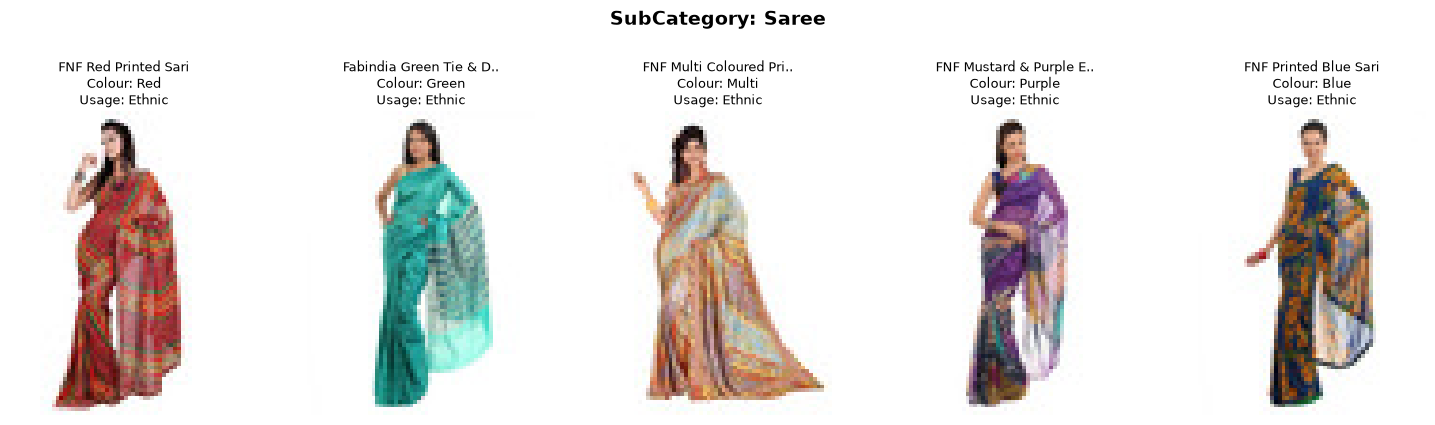

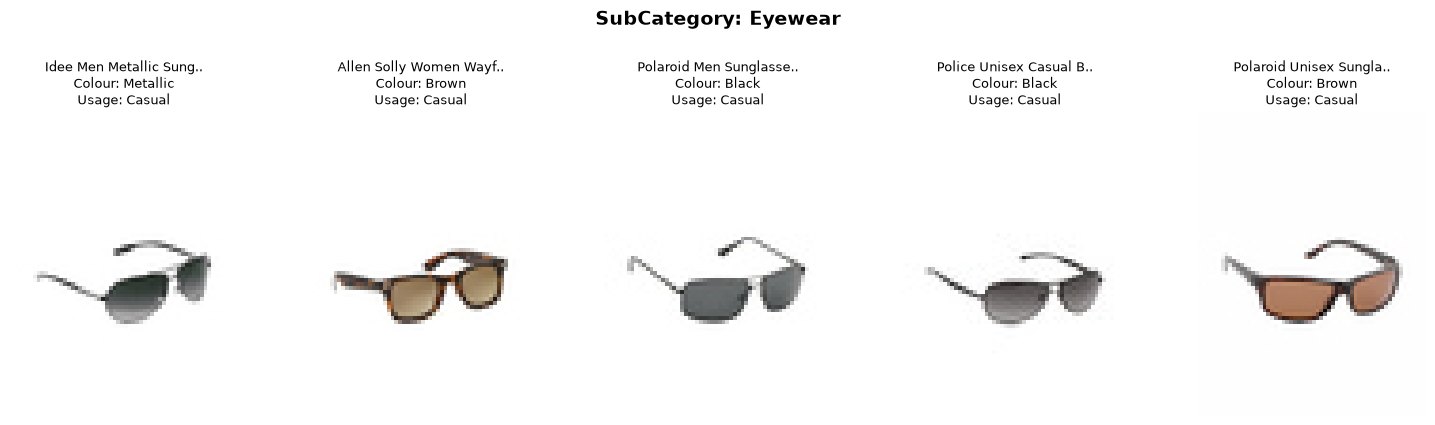

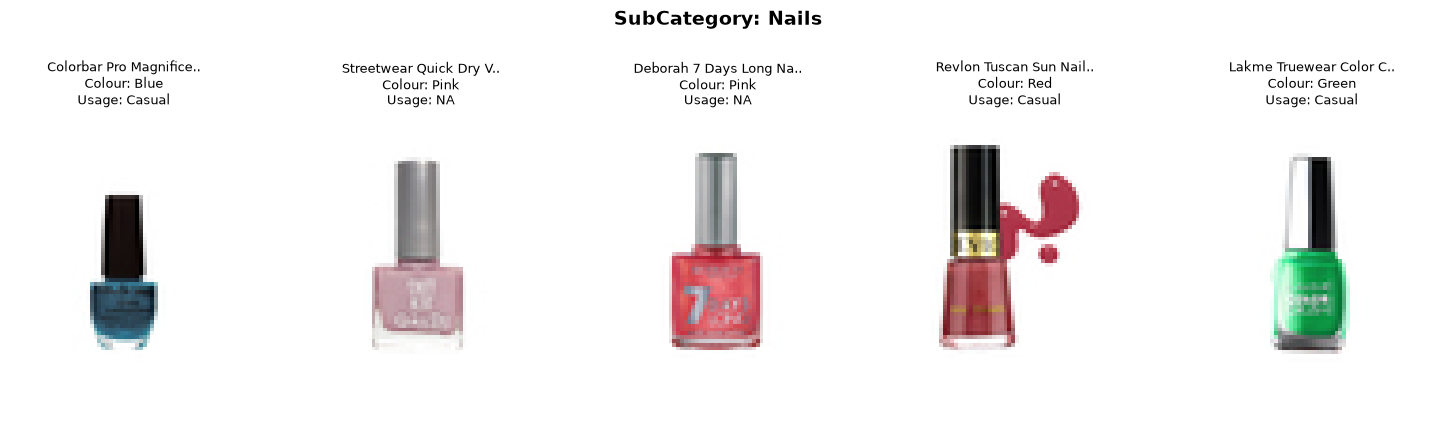

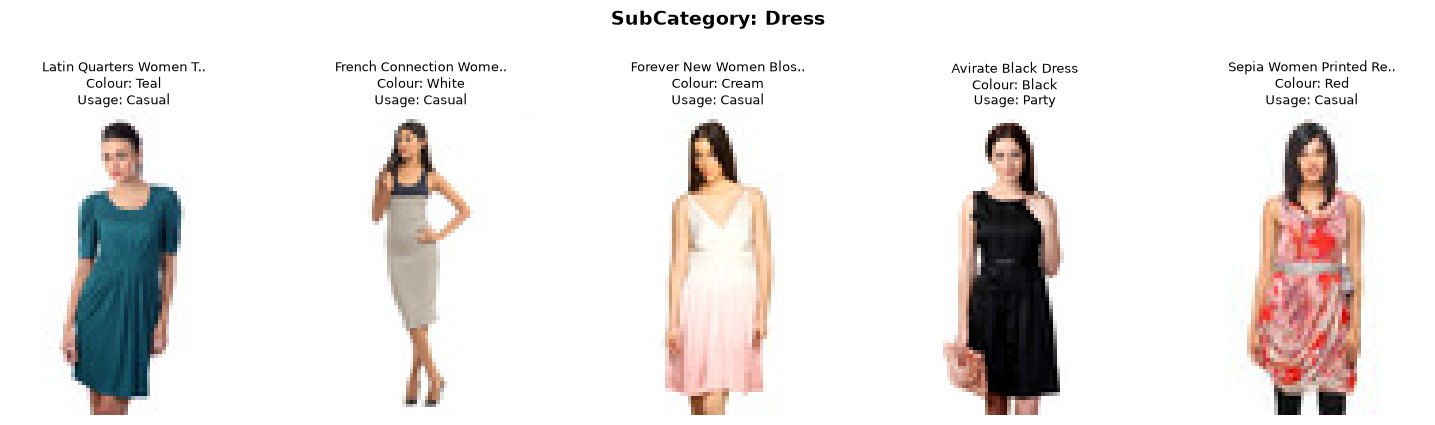

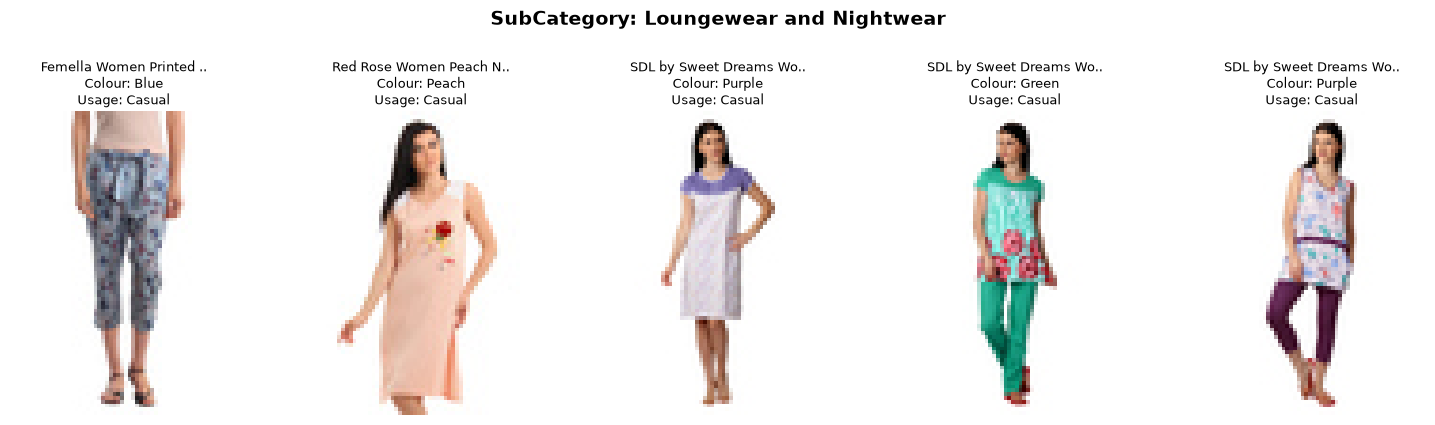

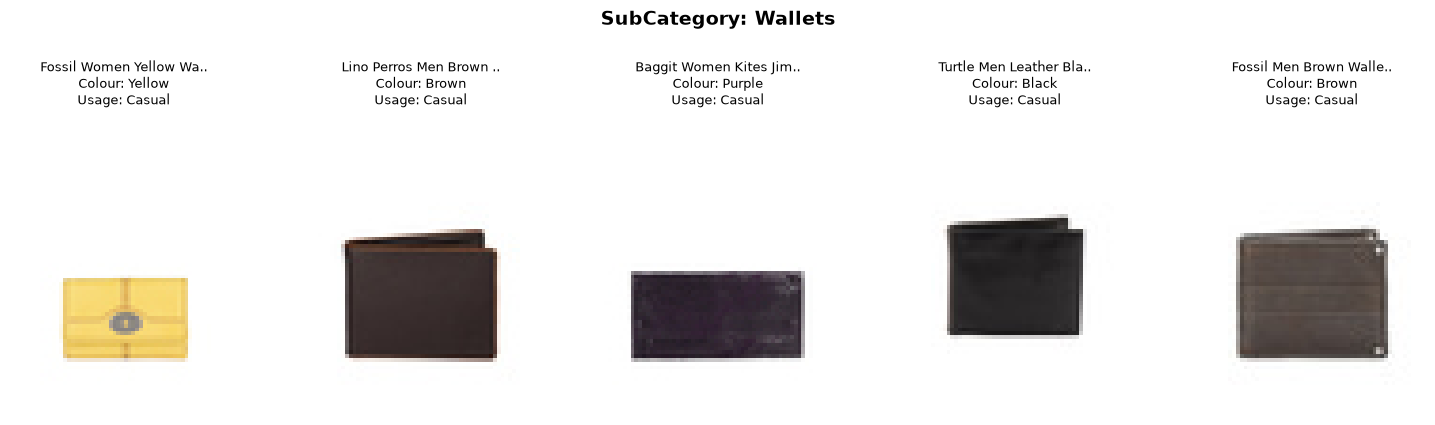

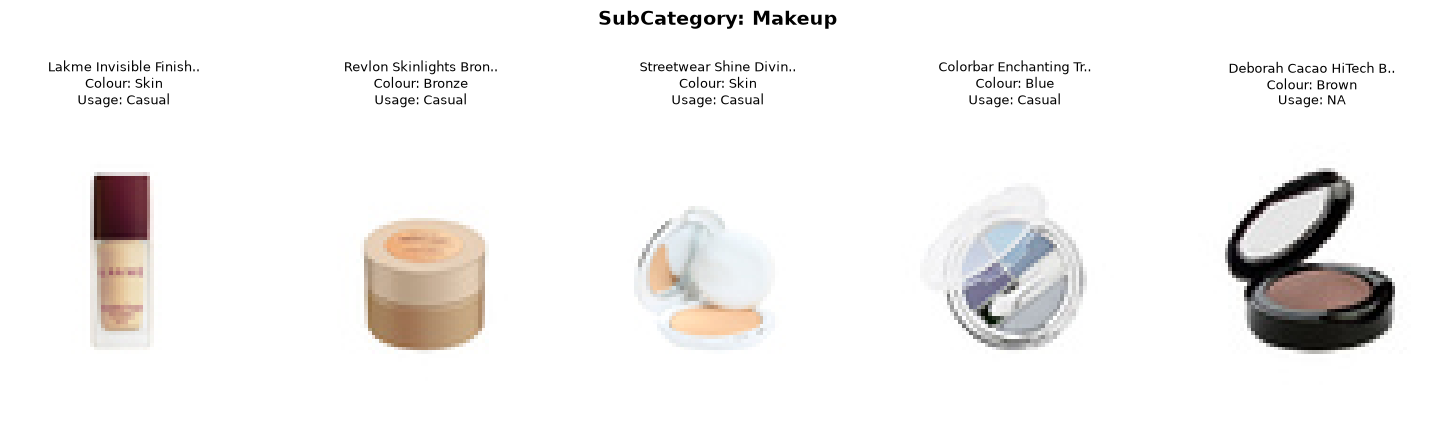

In [12]:
if "styles_final_filtered" in locals():
    df_sample = styles_final_filtered.copy()
else:
    df_sample = pd.read_csv("myntradataset/styles_cleaned.csv")

if "image_path" not in df_sample.columns:
    df_sample["image_path"] = df_sample["id"].apply(
        lambda pid: f"myntradataset/images/{pid}.jpg"
    )

subcategories = df_sample["subCategory"].unique()

for subcat in subcategories:
    sub_df = df_sample[df_sample["subCategory"] == subcat]
    sample_df = sub_df.sample(n=min(5, len(sub_df)), random_state=42)

    n_items = len(sample_df)
    fig, axes = plt.subplots(1, n_items, figsize=(3 * n_items, 4))

    if n_items == 1:
        axes = [axes]

    fig.suptitle(f"SubCategory: {subcat}", fontsize=14, fontweight="bold", y=1.05)

    for ax, (_, row) in zip(axes, sample_df.iterrows()):
        img_path = row["image_path"]

        if os.path.exists(img_path):
            try:
                img = Image.open(img_path)
                ax.imshow(img)
            except Exception:
                ax.text(
                    0.5, 0.5, "Image Corrupt", ha="center", va="center", color="red"
                )
        else:
            ax.text(
                0.5, 0.5, "Image Missing", ha="center", va="center", color="red"
            )

        ax.axis("off")

        name = str(row.get("productDisplayName", "N/A"))
        colour = str(row.get("baseColour", "N/A"))
        usage = str(row.get("usage", "N/A"))

        short_name = (name[:22] + "..") if len(name) > 22 else name

        ax.set_title(
            f"{short_name}\nColour: {colour}\nUsage: {usage}",
            fontsize=9,
            pad=5,
        )

    plt.tight_layout()
    plt.show()

## Check for the visibility of the GPU and available memory

In [16]:
is_cuda_available = torch.cuda.is_available()
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {is_cuda_available}")

if is_cuda_available:
    device = torch.device("cuda")
    device_name = torch.cuda.get_device_name(0)

    bytes_per_gb = 1024**3
    total_mem = (
        torch.cuda.get_device_properties(0).total_memory / bytes_per_gb
    )
    allocated_mem = torch.cuda.memory_allocated(0) / bytes_per_gb
    reserved_mem = torch.cuda.memory_reserved(0) / bytes_per_gb
    free_mem = total_mem - allocated_mem

    print("\n=== GPU Hardware Summary ===")
    print(f"Active Device       : {device_name}")
    print(f"Total VRAM         : {total_mem:.2f} GB")
    print(f"Allocated VRAM     : {allocated_mem:.2f} GB")
    print(f"Reserved VRAM      : {reserved_mem:.2f} GB")
    print(f"Estimated Free VRAM: {free_mem:.2f} GB")
else:
    device = torch.device("cpu")
    print(
        "\nCUDA device not detected! Running on CPU. Ensure NVIDIA drivers and CUDA-enabled PyTorch are installed."
    )

PyTorch Version: 2.14.1+cu130
CUDA Available: True

=== GPU Hardware Summary ===
Active Device       : NVIDIA GeForce RTX 3060 Laptop GPU
Total VRAM         : 5.67 GB
Allocated VRAM     : 0.00 GB
Reserved VRAM      : 0.00 GB
Estimated Free VRAM: 5.67 GB


## Keep the categories with >300 products. Preserve category proportions and take 10.000 products by random

In [18]:
if "styles_final_filtered" in locals():
    df_clean = styles_final_filtered.copy()
elif os.path.exists("myntradataset/styles_cleaned.csv"):
    df_clean = pd.read_csv("myntradataset/styles_cleaned.csv")
else:
    df_clean = pd.read_csv("myntradataset/styles.csv", on_bad_lines="skip")

THRESHOLD = 300
counts = df_clean["subCategory"].value_counts()
valid_cats = counts[counts >= THRESHOLD].index
df_filtered = df_clean[df_clean["subCategory"].isin(valid_cats)].copy()

SEED = 42
TARGET_SIZE = 10000

if len(df_filtered) > TARGET_SIZE:
    sampled_df, _ = train_test_split(
        df_filtered,
        train_size=TARGET_SIZE,
        stratify=df_filtered["subCategory"],
        random_state=SEED,
    )
else:
    sampled_df = df_filtered.copy()
    print(
        f"Dataset size ({len(df_filtered)}) is already less than target ({TARGET_SIZE}). Using all rows."
    )

orig_props = df_filtered["subCategory"].value_counts(normalize=True)
sample_props = sampled_df["subCategory"].value_counts(normalize=True)

comparison_df = pd.DataFrame(
    {
        "Original Count": df_filtered["subCategory"].value_counts(),
        "Sampled Count": sampled_df["subCategory"].value_counts(),
        "Original %": (orig_props * 100).round(2),
        "Sampled %": (sample_props * 100).round(2),
    }
)

print("=== Stratified Sampling Summary ===")
print(f"Total products before sampling : {len(df_filtered)}")
print(f"Total products selected        : {len(sampled_df)}")
print("\nCategory Distribution Comparison:")
print(comparison_df)

output_path = "myntradataset/styles_sampled_10k.csv"
sampled_df.to_csv(output_path, index=False)
print(f"\nSampled dataset saved to: {output_path}")


=== Stratified Sampling Summary ===
Total products before sampling : 42858
Total products selected        : 10000

Category Distribution Comparison:
                          Original Count  Sampled Count  Original %  Sampled %
subCategory                                                                   
Topwear                            15398           3593       35.93      35.93
Shoes                               7343           1713       17.13      17.13
Bags                                3055            713        7.13       7.13
Bottomwear                          2693            628        6.28       6.28
Watches                             2542            593        5.93       5.93
Innerwear                           1808            422        4.22       4.22
Jewellery                           1079            252        2.52       2.52
Eyewear                             1073            250        2.50       2.50
Fragrance                           1011            236      

## 70/15/15 and reuse the split for each model

In [19]:
if "sampled_df" in locals():
    df_dataset = sampled_df.copy()
elif os.path.exists("myntradataset/styles_sampled_10k.csv"):
    df_dataset = pd.read_csv("myntradataset/styles_sampled_10k.csv")
else:
    raise FileNotFoundError(
        "Sampled dataset 'styles_sampled_10k.csv' not found."
    )

SEED = 42

train_df, temp_df = train_test_split(
    df_dataset,
    test_size=0.30,
    stratify=df_dataset["subCategory"],
    random_state=SEED,
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["subCategory"],
    random_state=SEED,
)

train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

df_dataset_with_splits = pd.concat([train_df, val_df, test_df], axis=0)

output_dir = "myntradataset"
os.makedirs(output_dir, exist_ok=True)

train_df.to_csv(os.path.join(output_dir, "train_split.csv"), index=False)
val_df.to_csv(os.path.join(output_dir, "val_split.csv"), index=False)
test_df.to_csv(os.path.join(output_dir, "test_split.csv"), index=False)

df_dataset_with_splits.to_csv(
    os.path.join(output_dir, "styles_sampled_10k_splits.csv"), index=False
)

split_ids_df = df_dataset_with_splits[["id", "subCategory", "split"]]
split_ids_df.to_csv(
    os.path.join(output_dir, "product_splits_map.csv"), index=False
)

print("=== Stratified Dataset Split Summary ===")
print(
    f"Train Set : {len(train_df):>6} products ({len(train_df)/len(df_dataset):.1%})"
)
print(
    f"Val Set   : {len(val_df):>6} products ({len(val_df)/len(df_dataset):.1%})"
)
print(
    f"Test Set  : {len(test_df):>6} products ({len(test_df)/len(df_dataset):.1%})"
)
print(f"Total     : {len(df_dataset_with_splits):>6} products")

category_split_counts = pd.crosstab(
    df_dataset_with_splits["subCategory"], df_dataset_with_splits["split"]
)
print("\nProduct count per subCategory across splits:")
print(category_split_counts[["train", "val", "test"]])

=== Stratified Dataset Split Summary ===
Train Set :   7000 products (70.0%)
Val Set   :   1500 products (15.0%)
Test Set  :   1500 products (15.0%)
Total     :  10000 products

Product count per subCategory across splits:
split                     train  val  test
subCategory                               
Bags                        499  107   107
Belts                       132   29    28
Bottomwear                  440   94    94
Dress                        78   17    16
Eyewear                     175   37    38
Flip Flops                  149   32    32
Fragrance                   165   35    36
Innerwear                   296   63    63
Jewellery                   176   38    38
Lips                         86   18    19
Loungewear and Nightwear     77   17    16
Makeup                       50   11    11
Nails                        54   11    12
Sandal                      158   34    33
Saree                        69   15    15
Shoes                      1199  257   257
Soc

## Make the images 224 pixels. Apply some rotation, flips and jitter for training

In [23]:
IMG_SIZE = (224, 224)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose(
    [
        transforms.Resize(IMG_SIZE),
        transforms.RandomRotation(degrees=15),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ColorJitter(
            brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05
        ),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)

val_test_transform = transforms.Compose(
    [
        transforms.Resize(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)

if "df_dataset_with_splits" in locals():
    master_df = df_dataset_with_splits
else:
    master_df = pd.read_csv("myntradataset/styles_sampled_10k_splits.csv")

unique_categories = sorted(master_df["subCategory"].unique())
category_to_idx = {cat: idx for idx, cat in enumerate(unique_categories)}
idx_to_category = {idx: cat for cat, idx in category_to_idx.items()}

print(f"Mapped {len(unique_categories)} subCategory classes.")


class MyntraFashionDataset(Dataset):

    def __init__(
        self,
        df,
        img_dir="myntradataset/images",
        transform=None,
        label_map=None,
    ):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform
        self.label_map = label_map

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        product_id = str(row["id"]).split(".")[0].strip()

        if "image_path" in row and pd.notna(row["image_path"]):
            img_path = row["image_path"]
        else:
            img_path = os.path.join(self.img_dir, f"{product_id}.jpg")

        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label_name = row["subCategory"]
        label_idx = (
            self.label_map[label_name] if self.label_map else label_name
        )

        return image, torch.tensor(label_idx, dtype=torch.long)


if "train_df" not in locals():
    train_df = pd.read_csv("myntradataset/train_split.csv")
    val_df = pd.read_csv("myntradataset/val_split.csv")
    test_df = pd.read_csv("myntradataset/test_split.csv")

train_dataset = MyntraFashionDataset(
    train_df, transform=train_transform, label_map=category_to_idx
)
val_dataset = MyntraFashionDataset(
    val_df, transform=val_test_transform, label_map=category_to_idx
)
test_dataset = MyntraFashionDataset(
    test_df, transform=val_test_transform, label_map=category_to_idx
)

BATCH_SIZE = 32
NUM_WORKERS = 2 if os.name != "nt" else 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

sample_images, sample_labels = next(iter(train_loader))

print("\n=== DataLoader Batch Verification ===")
print(f"Batch image tensor shape : {sample_images.shape}")
print(f"Batch label tensor shape : {sample_labels.shape}")
print(f"Min normalized pixel val : {sample_images.min():.4f}")
print(f"Max normalized pixel val : {sample_images.max():.4f}")

Mapped 20 subCategory classes.

=== DataLoader Batch Verification ===
Batch image tensor shape : torch.Size([32, 3, 224, 224])
Batch label tensor shape : torch.Size([32])
Min normalized pixel val : -2.1179
Max normalized pixel val : 2.6400


## Text model with DistilBERT

In [27]:
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
MAX_LEN = 64


def prepare_text_feature(df):
    df = df.copy()

    name = df["productDisplayName"].fillna("").astype(str)
    colour = df["baseColour"].fillna("").astype(str)
    usage = df["usage"].fillna("").astype(str)

    df["text_input"] = (
        "Product: " + name + ". Color: " + colour + ". Usage: " + usage + "."
    )
    return df


class MyntraTextDataset(Dataset):

    def __init__(self, df, tokenizer, max_len=64, label_map=None):
        self.df = prepare_text_feature(df).reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len = max_len
        self.label_map = label_map

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        text = row["text_input"]

        encoding = self.tokenizer(
            text,
            max_length=self.max_len,
            padding="max_length",
            truncation=True,
            return_attention_mask=True,
            return_tensors="pt",
        )

        label_name = row["subCategory"]
        label_idx = (
            self.label_map[label_name] if self.label_map else label_name
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0), 
            "attention_mask": encoding["attention_mask"].squeeze(
                0
            ), 
            "label": torch.tensor(label_idx, dtype=torch.long),
        }


if "df_dataset_with_splits" in locals():
    master_df = df_dataset_with_splits
else:
    master_df = pd.read_csv("myntradataset/styles_sampled_10k_splits.csv")

unique_categories = sorted(master_df["subCategory"].unique())
category_to_idx = {cat: idx for idx, cat in enumerate(unique_categories)}

if "train_df" not in locals():
    train_df = pd.read_csv("myntradataset/train_split.csv")
    val_df = pd.read_csv("myntradataset/val_split.csv")
    test_df = pd.read_csv("myntradataset/test_split.csv")

train_text_dataset = MyntraTextDataset(
    train_df, tokenizer, max_len=MAX_LEN, label_map=category_to_idx
)
val_text_dataset = MyntraTextDataset(
    val_df, tokenizer, max_len=MAX_LEN, label_map=category_to_idx
)
test_text_dataset = MyntraTextDataset(
    test_df, tokenizer, max_len=MAX_LEN, label_map=category_to_idx
)

BATCH_SIZE = 32
NUM_WORKERS = 2 if os.name != "nt" else 0

train_text_loader = DataLoader(
    train_text_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)
val_text_loader = DataLoader(
    val_text_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)
test_text_loader = DataLoader(
    test_text_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

sample_batch = next(iter(train_text_loader))
print("=== DistilBERT Text Tokenization Batch Verification ===")
print("Sample Combined Input Text:")
print(f"  '{train_text_dataset.df['text_input'].iloc[0]}'")
print(f"\ninput_ids shape      : {sample_batch['input_ids'].shape}")
print(f"attention_mask shape : {sample_batch['attention_mask'].shape}")
print(f"label tensor shape   : {sample_batch['label'].shape}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

=== DistilBERT Text Tokenization Batch Verification ===
Sample Combined Input Text:
  'Product: Mod'acc Women Blue Handbag. Color: Blue. Usage: Casual.'

input_ids shape      : torch.Size([32, 64])
attention_mask shape : torch.Size([32, 64])
label tensor shape   : torch.Size([32])


## Build the models

In [29]:
num_classes = len(category_to_idx)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def print_trainable_parameters(model, model_name):
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )
    print(f"=== {model_name} Parameter Summary ===")
    print(f"Total Parameters     : {total_params:,}")
    print(f"Trainable Parameters : {trainable_params:,}")
    print(
        f"Frozen Parameters    : {total_params - trainable_params:,} ({(1 - trainable_params/total_params):.2%})\n"
    )


class ResNet18ImageClassifier(nn.Module):

    def __init__(self, num_classes, freeze_backbone=True):
        super().__init__()
        self.resnet = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT
        )
        in_features = self.resnet.fc.in_features

        if freeze_backbone:
            for param in self.resnet.parameters():
                param.requires_grad = False

        self.resnet.fc = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes),
        )

    def forward(self, images):
        return self.resnet(images)


class DistilBERTTextClassifier(nn.Module):

    def __init__(
        self,
        model_name="distilbert-base-uncased",
        num_classes=20,
        freeze_backbone=True,
    ):
        super().__init__()
        self.bert = DistilBertModel.from_pretrained(model_name)
        hidden_size = self.bert.config.hidden_size 

        if freeze_backbone:
            for param in self.bert.parameters():
                param.requires_grad = False

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes),
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_output = outputs.last_hidden_state[:, 0, :]
        logits = self.classifier(cls_output)
        return logits


class MultimodalClassifier(nn.Module):

    def __init__(
        self,
        text_model_name="distilbert-base-uncased",
        num_classes=20,
        freeze_backbones=True,
    ):
        super().__init__()

        resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        img_feature_dim = resnet.fc.in_features 
        resnet.fc = nn.Identity()
        self.image_encoder = resnet

        self.text_encoder = DistilBertModel.from_pretrained(text_model_name)
        text_feature_dim = self.text_encoder.config.hidden_size  # 768

        if freeze_backbones:
            for param in self.image_encoder.parameters():
                param.requires_grad = False
            for param in self.text_encoder.parameters():
                param.requires_grad = False

        fusion_dim = img_feature_dim + text_feature_dim 
        self.mlp_head = nn.Sequential(
            nn.Linear(fusion_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, images, input_ids, attention_mask):
        img_features = self.image_encoder(images)

        text_outputs = self.text_encoder(
            input_ids=input_ids, attention_mask=attention_mask
        )
        text_features = text_outputs.last_hidden_state[:, 0, :]

        combined_features = torch.cat((img_features, text_features), dim=1)

        logits = self.mlp_head(combined_features)
        return logits

model_image = ResNet18ImageClassifier(
    num_classes=num_classes, freeze_backbone=True
).to(device)
model_text = DistilBERTTextClassifier(
    num_classes=num_classes, freeze_backbone=True
).to(device)
model_multimodal = MultimodalClassifier(
    num_classes=num_classes, freeze_backbones=True
).to(device)

print_trainable_parameters(model_image, "1. ResNet18 Image-Only Model")
print_trainable_parameters(model_text, "2. DistilBERT Text-Only Model")
print_trainable_parameters(
    model_multimodal, "3. Multimodal (Image + Text) Model"
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/omar/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|█████████████████████████████████████| 44.7M/44.7M [00:02<00:00, 20.8MB/s]


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


=== 1. ResNet18 Image-Only Model Parameter Summary ===
Total Parameters     : 11,312,980
Trainable Parameters : 136,468
Frozen Parameters    : 11,176,512 (98.79%)

=== 2. DistilBERT Text-Only Model Parameter Summary ===
Total Parameters     : 66,564,884
Trainable Parameters : 202,004
Frozen Parameters    : 66,362,880 (99.70%)

=== 3. Multimodal (Image + Text) Model Parameter Summary ===
Total Parameters     : 77,872,980
Trainable Parameters : 333,588
Frozen Parameters    : 77,539,392 (99.57%)



## Train the models

In [31]:
class MyntraMultimodalDataset(Dataset):
    def __init__(self, df, img_dir="myntradataset/images", img_transform=None, tokenizer=None, max_len=64, label_map=None):
        self.df = prepare_text_feature(df).reset_index(drop=True)
        self.img_dir = img_dir
        self.img_transform = img_transform
        self.tokenizer = tokenizer
        self.max_len = max_len
        self.label_map = label_map

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        product_id = str(row["id"]).split(".")[0].strip()

        if "image_path" in row and pd.notna(row["image_path"]):
            img_path = row["image_path"]
        else:
            img_path = os.path.join(self.img_dir, f"{product_id}.jpg")
        
        image = Image.open(img_path).convert("RGB")
        if self.img_transform:
            image = self.img_transform(image)

        text = row["text_input"]
        encoding = self.tokenizer(
            text,
            max_length=self.max_len,
            padding="max_length",
            truncation=True,
            return_attention_mask=True,
            return_tensors="pt"
        )

        label_name = row["subCategory"]
        label_idx = self.label_map[label_name] if self.label_map else label_name

        return {
            "image": image,
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "label": torch.tensor(label_idx, dtype=torch.long)
        }

train_mm_dataset = MyntraMultimodalDataset(train_df, img_transform=train_transform, tokenizer=tokenizer, max_len=MAX_LEN, label_map=category_to_idx)
val_mm_dataset = MyntraMultimodalDataset(val_df, img_transform=val_test_transform, tokenizer=tokenizer, max_len=MAX_LEN, label_map=category_to_idx)

train_mm_loader = DataLoader(train_mm_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_mm_loader = DataLoader(val_mm_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

def train_and_evaluate(model, train_loader, val_loader, model_type, model_name, epochs=3, lr=1e-3, weight_decay=1e-2):
    criterion = nn.CrossEntropyLoss()
    optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=weight_decay)
    
    os.makedirs("checkpoints", exist_ok=True)
    checkpoint_path = f"checkpoints/best_{model_name}.pt"
    
    best_val_f1 = 0.0
    history = []
    total_start_time = time.time()

    print(f"\n==================================================")
    print(f" Starting Trial: {model_name} ({epochs} Epochs)")
    print(f"==================================================")

    for epoch in range(1, epochs + 1):
        epoch_start = time.time()
        
        model.train()
        train_loss, train_preds, train_targets = 0.0, [], []

        for batch in train_loader:
            optimizer.zero_grad()

            if model_type == "image":
                images, labels = batch
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
            elif model_type == "text":
                input_ids = batch["input_ids"].to(device)
                attention_mask = batch["attention_mask"].to(device)
                labels = batch["label"].to(device)
                outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            elif model_type == "multimodal":
                images = batch["image"].to(device)
                input_ids = batch["input_ids"].to(device)
                attention_mask = batch["attention_mask"].to(device)
                labels = batch["label"].to(device)
                outputs = model(images, input_ids, attention_mask)

            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * labels.size(0)
            preds = torch.argmax(outputs, dim=1)
            train_preds.extend(preds.cpu().numpy())
            train_targets.extend(labels.cpu().numpy())

        train_epoch_loss = train_loss / len(train_loader.dataset)
        train_acc = accuracy_score(train_targets, train_preds)
        train_f1 = f1_score(train_targets, train_preds, average="macro", zero_division=0)

        model.eval()
        val_loss, val_preds, val_targets = 0.0, [], []

        with torch.no_grad():
            for batch in val_loader:
                if model_type == "image":
                    images, labels = batch
                    images, labels = images.to(device), labels.to(device)
                    outputs = model(images)
                elif model_type == "text":
                    input_ids = batch["input_ids"].to(device)
                    attention_mask = batch["attention_mask"].to(device)
                    labels = batch["label"].to(device)
                    outputs = model(input_ids=input_ids, attention_mask=attention_mask)
                elif model_type == "multimodal":
                    images = batch["image"].to(device)
                    input_ids = batch["input_ids"].to(device)
                    attention_mask = batch["attention_mask"].to(device)
                    labels = batch["label"].to(device)
                    outputs = model(images, input_ids, attention_mask)

                loss = criterion(outputs, labels)
                val_loss += loss.item() * labels.size(0)
                preds = torch.argmax(outputs, dim=1)
                val_preds.extend(preds.cpu().numpy())
                val_targets.extend(labels.cpu().numpy())

        val_epoch_loss = val_loss / len(val_loader.dataset)
        val_acc = accuracy_score(val_targets, val_preds)
        val_f1 = f1_score(val_targets, val_preds, average="macro", zero_division=0)
        epoch_duration = time.time() - epoch_start

        is_best = val_f1 > best_val_f1
        if is_best:
            best_val_f1 = val_f1
            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_f1": val_f1,
                "val_acc": val_acc,
                "category_map": category_to_idx
            }, checkpoint_path)

        history.append({
            "epoch": epoch,
            "train_loss": train_epoch_loss,
            "train_acc": train_acc,
            "train_f1": train_f1,
            "val_loss": val_epoch_loss,
            "val_acc": val_acc,
            "val_f1": val_f1,
            "epoch_time_sec": epoch_duration
        })

        print(f"Epoch [{epoch}/{epochs}] ({epoch_duration:.1f}s) | "
              f"Train Loss: {train_epoch_loss:.4f} Acc: {train_acc:.4f} F1: {train_f1:.4f} | "
              f"Val Loss: {val_epoch_loss:.4f} Acc: {val_acc:.4f} F1: {val_f1:.4f} "
              f"{'★ Saved Best' if is_best else ''}")

    total_duration = time.time() - total_start_time
    print(f"Trial Completed in {total_duration:.2f} seconds. Best Val Macro F1: {best_val_f1:.4f}")
    
    log_path = f"checkpoints/log_{model_name}.json"
    with open(log_path, "w") as f:
        json.dump({"model_name": model_name, "total_time_sec": total_duration, "history": history}, f, indent=4)

    return history, total_duration, best_val_f1, checkpoint_path


TRIAL_EPOCHS = 3
BATCH_SIZE = 32

results_summary = []

model_image = ResNet18ImageClassifier(num_classes=num_classes, freeze_backbone=True).to(device)
hist_img, time_img, best_f1_img, ckpt_img = train_and_evaluate(
    model_image, train_loader, val_loader, 
    model_type="image", model_name="resnet18_image_only", epochs=TRIAL_EPOCHS
)
results_summary.append({"Model": "ResNet18 Image-Only", "Time (s)": round(time_img, 2), "Best Val Macro F1": round(best_f1_img, 4), "Checkpoint": ckpt_img})

model_text = DistilBERTTextClassifier(num_classes=num_classes, freeze_backbone=True).to(device)
hist_txt, time_txt, best_f1_txt, ckpt_txt = train_and_evaluate(
    model_text, train_text_loader, val_text_loader, 
    model_type="text", model_name="distilbert_text_only", epochs=TRIAL_EPOCHS
)
results_summary.append({"Model": "DistilBERT Text-Only", "Time (s)": round(time_txt, 2), "Best Val Macro F1": round(best_f1_txt, 4), "Checkpoint": ckpt_txt})

model_multimodal = MultimodalClassifier(num_classes=num_classes, freeze_backbones=True).to(device)
hist_mm, time_mm, best_f1_mm, ckpt_mm = train_and_evaluate(
    model_multimodal, train_mm_loader, val_mm_loader, 
    model_type="multimodal", model_name="multimodal_resnet_distilbert", epochs=TRIAL_EPOCHS
)
results_summary.append({"Model": "Multimodal (Image + Text)", "Time (s)": round(time_mm, 2), "Best Val Macro F1": round(best_f1_mm, 4), "Checkpoint": ckpt_mm})


summary_df = pd.DataFrame(results_summary)
print("\n" + "="*60)
print("             TRAINING TRIAL SUMMARY & TIMING             ")
print("="*60)
print(summary_df.to_string(index=False))


 Starting Trial: resnet18_image_only (3 Epochs)
Epoch [1/3] (14.5s) | Train Loss: 1.1140 Acc: 0.7026 F1: 0.3887 | Val Loss: 0.5782 Acc: 0.8387 F1: 0.5948 ★ Saved Best
Epoch [2/3] (12.5s) | Train Loss: 0.6222 Acc: 0.8221 F1: 0.5955 | Val Loss: 0.4604 Acc: 0.8613 F1: 0.6599 ★ Saved Best
Epoch [3/3] (13.4s) | Train Loss: 0.5117 Acc: 0.8461 F1: 0.6507 | Val Loss: 0.4284 Acc: 0.8727 F1: 0.7380 ★ Saved Best
Trial Completed in 40.62 seconds. Best Val Macro F1: 0.7380


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



 Starting Trial: distilbert_text_only (3 Epochs)
Epoch [1/3] (12.7s) | Train Loss: 1.7454 Acc: 0.5289 F1: 0.1222 | Val Loss: 1.1755 Acc: 0.6700 F1: 0.2178 ★ Saved Best
Epoch [2/3] (12.8s) | Train Loss: 1.0573 Acc: 0.6914 F1: 0.3371 | Val Loss: 0.7830 Acc: 0.7807 F1: 0.4891 ★ Saved Best
Epoch [3/3] (13.0s) | Train Loss: 0.7594 Acc: 0.7786 F1: 0.5302 | Val Loss: 0.5362 Acc: 0.8327 F1: 0.6833 ★ Saved Best
Trial Completed in 39.89 seconds. Best Val Macro F1: 0.6833


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



 Starting Trial: multimodal_resnet_distilbert (3 Epochs)
Epoch [1/3] (21.3s) | Train Loss: 0.5827 Acc: 0.8559 F1: 0.6709 | Val Loss: 0.2252 Acc: 0.9320 F1: 0.8512 ★ Saved Best
Epoch [2/3] (21.6s) | Train Loss: 0.2166 Acc: 0.9429 F1: 0.8815 | Val Loss: 0.1602 Acc: 0.9473 F1: 0.8988 ★ Saved Best
Epoch [3/3] (22.2s) | Train Loss: 0.1577 Acc: 0.9569 F1: 0.9161 | Val Loss: 0.1213 Acc: 0.9647 F1: 0.9261 ★ Saved Best
Trial Completed in 66.50 seconds. Best Val Macro F1: 0.9261

             TRAINING TRIAL SUMMARY & TIMING             
                    Model  Time (s)  Best Val Macro F1                                       Checkpoint
      ResNet18 Image-Only     40.62             0.7380          checkpoints/best_resnet18_image_only.pt
     DistilBERT Text-Only     39.89             0.6833         checkpoints/best_distilbert_text_only.pt
Multimodal (Image + Text)     66.50             0.9261 checkpoints/best_multimodal_resnet_distilbert.pt


## Repeat the runs with weighted loss, compare validation macro F1 with unweighted logs

In [33]:
train_labels = train_df["subCategory"].map(category_to_idx).values
classes = np.unique(train_labels)

class_weights_np = compute_class_weight(
    class_weight="balanced", classes=classes, y=train_labels
)

class_weights_tensor = torch.tensor(class_weights_np, dtype=torch.float).to(
    device
)

print("=== Class Weights Summary (Calculated from Train Split Only) ===")
for cat, idx in sorted(category_to_idx.items(), key=lambda x: x[1]):
    count = (train_labels == idx).sum()
    weight = class_weights_np[idx]
    print(f"Class {idx:2d} | {cat:<25} | Train Count: {count:>4} | Weight: {weight:.4f}")

def train_and_evaluate_weighted(
    model,
    train_loader,
    val_loader,
    model_type,
    model_name,
    epochs=3,
    lr=1e-3,
    weight_decay=1e-2,
    class_weights=None,
):
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr,
        weight_decay=weight_decay,
    )

    os.makedirs("checkpoints", exist_ok=True)
    checkpoint_path = f"checkpoints/best_{model_name}_weighted.pt"

    best_val_f1 = 0.0
    history = []
    total_start_time = time.time()

    print(f"\n==================================================")
    print(f" Starting Class-Weighted Trial: {model_name} ({epochs} Epochs)")
    print(f"==================================================")

    for epoch in range(1, epochs + 1):
        epoch_start = time.time()

        model.train()
        train_loss, train_preds, train_targets = 0.0, [], []

        for batch in train_loader:
            optimizer.zero_grad()

            if model_type == "image":
                images, labels = batch
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
            elif model_type == "text":
                input_ids = batch["input_ids"].to(device)
                attention_mask = batch["attention_mask"].to(device)
                labels = batch["label"].to(device)
                outputs = model(
                    input_ids=input_ids, attention_mask=attention_mask
                )
            elif model_type == "multimodal":
                images = batch["image"].to(device)
                input_ids = batch["input_ids"].to(device)
                attention_mask = batch["attention_mask"].to(device)
                labels = batch["label"].to(device)
                outputs = model(images, input_ids, attention_mask)

            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * labels.size(0)
            preds = torch.argmax(outputs, dim=1)
            train_preds.extend(preds.cpu().numpy())
            train_targets.extend(labels.cpu().numpy())

        train_epoch_loss = train_loss / len(train_loader.dataset)
        train_acc = accuracy_score(train_targets, train_preds)
        train_f1 = f1_score(
            train_targets, train_preds, average="macro", zero_division=0
        )

        model.eval()
        val_loss, val_preds, val_targets = 0.0, [], []

        with torch.no_grad():
            for batch in val_loader:
                if model_type == "image":
                    images, labels = batch
                    images, labels = images.to(device), labels.to(device)
                    outputs = model(images)
                elif model_type == "text":
                    input_ids = batch["input_ids"].to(device)
                    attention_mask = batch["attention_mask"].to(device)
                    labels = batch["label"].to(device)
                    outputs = model(
                        input_ids=input_ids, attention_mask=attention_mask
                    )
                elif model_type == "multimodal":
                    images = batch["image"].to(device)
                    input_ids = batch["input_ids"].to(device)
                    attention_mask = batch["attention_mask"].to(device)
                    labels = batch["label"].to(device)
                    outputs = model(images, input_ids, attention_mask)

                loss = criterion(outputs, labels)
                val_loss += loss.item() * labels.size(0)
                preds = torch.argmax(outputs, dim=1)
                val_preds.extend(preds.cpu().numpy())
                val_targets.extend(labels.cpu().numpy())

        val_epoch_loss = val_loss / len(val_loader.dataset)
        val_acc = accuracy_score(val_targets, val_preds)
        val_f1 = f1_score(
            val_targets, val_preds, average="macro", zero_division=0
        )
        epoch_duration = time.time() - epoch_start

        is_best = val_f1 > best_val_f1
        if is_best:
            best_val_f1 = val_f1
            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "val_f1": val_f1,
                    "val_acc": val_acc,
                    "class_weights": class_weights_np,
                    "category_map": category_to_idx,
                },
                checkpoint_path,
            )

        history.append(
            {
                "epoch": epoch,
                "train_loss": train_epoch_loss,
                "train_acc": train_acc,
                "train_f1": train_f1,
                "val_loss": val_epoch_loss,
                "val_acc": val_acc,
                "val_f1": val_f1,
                "epoch_time_sec": epoch_duration,
            }
        )

        print(
            f"Epoch [{epoch}/{epochs}] ({epoch_duration:.1f}s) | "
            f"Train Loss: {train_epoch_loss:.4f} Acc: {train_acc:.4f} F1: {train_f1:.4f} | "
            f"Val Loss: {val_epoch_loss:.4f} Acc: {val_acc:.4f} F1: {val_f1:.4f} "
            f"{'★ Saved Best' if is_best else ''}"
        )

    total_duration = time.time() - total_start_time

    log_path = f"checkpoints/log_{model_name}_weighted.json"
    with open(log_path, "w") as f:
        json.dump(
            {
                "model_name": f"{model_name}_weighted",
                "total_time_sec": total_duration,
                "history": history,
            },
            f,
            indent=4,
        )

    return history, total_duration, best_val_f1, checkpoint_path


weighted_results = []

model_image_w = ResNet18ImageClassifier(
    num_classes=num_classes, freeze_backbone=True
).to(device)
hist_img_w, time_img_w, best_f1_img_w, ckpt_img_w = train_and_evaluate_weighted(
    model_image_w,
    train_loader,
    val_loader,
    model_type="image",
    model_name="resnet18_image_only",
    epochs=TRIAL_EPOCHS,
    class_weights=class_weights_tensor,
)
weighted_results.append(
    {
        "Model": "ResNet18 Image-Only",
        "Weighted Val Macro F1": round(best_f1_img_w, 4),
    }
)

model_text_w = DistilBERTTextClassifier(
    num_classes=num_classes, freeze_backbone=True
).to(device)
hist_txt_w, time_txt_w, best_f1_txt_w, ckpt_txt_w = train_and_evaluate_weighted(
    model_text_w,
    train_text_loader,
    val_text_loader,
    model_type="text",
    model_name="distilbert_text_only",
    epochs=TRIAL_EPOCHS,
    class_weights=class_weights_tensor,
)
weighted_results.append(
    {
        "Model": "DistilBERT Text-Only",
        "Weighted Val Macro F1": round(best_f1_txt_w, 4),
    }
)

model_multimodal_w = MultimodalClassifier(
    num_classes=num_classes, freeze_backbones=True
).to(device)
hist_mm_w, time_mm_w, best_f1_mm_w, ckpt_mm_w = train_and_evaluate_weighted(
    model_multimodal_w,
    train_mm_loader,
    val_mm_loader,
    model_type="multimodal",
    model_name="multimodal_resnet_distilbert",
    epochs=TRIAL_EPOCHS,
    class_weights=class_weights_tensor,
)
weighted_results.append(
    {
        "Model": "Multimodal (Image + Text)",
        "Weighted Val Macro F1": round(best_f1_mm_w, 4),
    }
)

unweighted_f1s = [best_f1_img, best_f1_txt, best_f1_mm]
weighted_f1s = [best_f1_img_w, best_f1_txt_w, best_f1_mm_w]

comparison_df = pd.DataFrame(
    {
        "Model Architecture": [
            "ResNet18 Image-Only",
            "DistilBERT Text-Only",
            "Multimodal (Image + Text)",
        ],
        "Unweighted Val Macro F1": [round(f1, 4) for f1 in unweighted_f1s],
        "Weighted Val Macro F1": [round(f1, 4) for f1 in weighted_f1s],
        "F1 Delta (Weighted - Unweighted)": [
            round(w - u, 4) for w, u in zip(weighted_f1s, unweighted_f1s)
        ],
    }
)

print("\n" + "=" * 75)
print("       COMPARISON: UNWEIGHTED vs. CLASS-WEIGHTED LOSS (MACRO F1)       ")
print("=" * 75)
print(comparison_df.to_string(index=False))

=== Class Weights Summary (Calculated from Train Split Only) ===
Class  0 | Bags                      | Train Count:  499 | Weight: 0.7014
Class  1 | Belts                     | Train Count:  132 | Weight: 2.6515
Class  2 | Bottomwear                | Train Count:  440 | Weight: 0.7955
Class  3 | Dress                     | Train Count:   78 | Weight: 4.4872
Class  4 | Eyewear                   | Train Count:  175 | Weight: 2.0000
Class  5 | Flip Flops                | Train Count:  149 | Weight: 2.3490
Class  6 | Fragrance                 | Train Count:  165 | Weight: 2.1212
Class  7 | Innerwear                 | Train Count:  296 | Weight: 1.1824
Class  8 | Jewellery                 | Train Count:  176 | Weight: 1.9886
Class  9 | Lips                      | Train Count:   86 | Weight: 4.0698
Class 10 | Loungewear and Nightwear  | Train Count:   77 | Weight: 4.5455
Class 11 | Makeup                    | Train Count:   50 | Weight: 7.0000
Class 12 | Nails                     | Train Co

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



 Starting Class-Weighted Trial: distilbert_text_only (3 Epochs)
Epoch [1/3] (13.1s) | Train Loss: 2.5701 Acc: 0.2970 F1: 0.2145 | Val Loss: 1.7753 Acc: 0.6720 F1: 0.5036 ★ Saved Best
Epoch [2/3] (13.1s) | Train Loss: 1.5461 Acc: 0.5593 F1: 0.4738 | Val Loss: 1.0171 Acc: 0.6667 F1: 0.6135 ★ Saved Best
Epoch [3/3] (13.1s) | Train Loss: 1.0695 Acc: 0.6573 F1: 0.5853 | Val Loss: 0.7134 Acc: 0.7707 F1: 0.7349 ★ Saved Best


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



 Starting Class-Weighted Trial: multimodal_resnet_distilbert (3 Epochs)
Epoch [1/3] (19.1s) | Train Loss: 0.9130 Acc: 0.7581 F1: 0.6586 | Val Loss: 0.3187 Acc: 0.8767 F1: 0.8293 ★ Saved Best
Epoch [2/3] (19.3s) | Train Loss: 0.3514 Acc: 0.8889 F1: 0.8283 | Val Loss: 0.2410 Acc: 0.9160 F1: 0.8729 ★ Saved Best
Epoch [3/3] (21.2s) | Train Loss: 0.2438 Acc: 0.9190 F1: 0.8766 | Val Loss: 0.2311 Acc: 0.9267 F1: 0.8813 ★ Saved Best

       COMPARISON: UNWEIGHTED vs. CLASS-WEIGHTED LOSS (MACRO F1)       
       Model Architecture  Unweighted Val Macro F1  Weighted Val Macro F1  F1 Delta (Weighted - Unweighted)
      ResNet18 Image-Only                   0.7380                 0.7428                            0.0048
     DistilBERT Text-Only                   0.6833                 0.7349                            0.0516
Multimodal (Image + Text)                   0.9261                 0.8813                           -0.0447


## Evaluate the models

Evaluating best models on shared test set...

            SHARED TEST SET PERFORMANCE COMPARISON            
       Model Architecture Accuracy Macro F1 Weighted F1
      ResNet18 Image-Only   0.8613   0.7062      0.8537
     DistilBERT Text-Only   0.8193   0.6461      0.7817
Multimodal (Image + Text)   0.9627   0.9179      0.9628


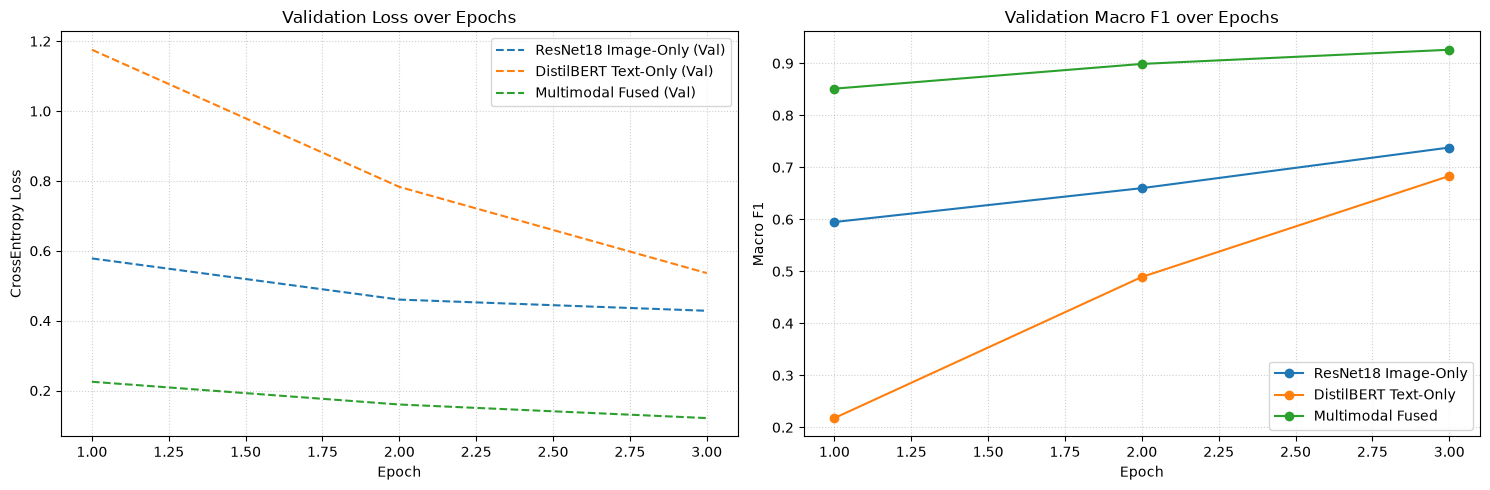

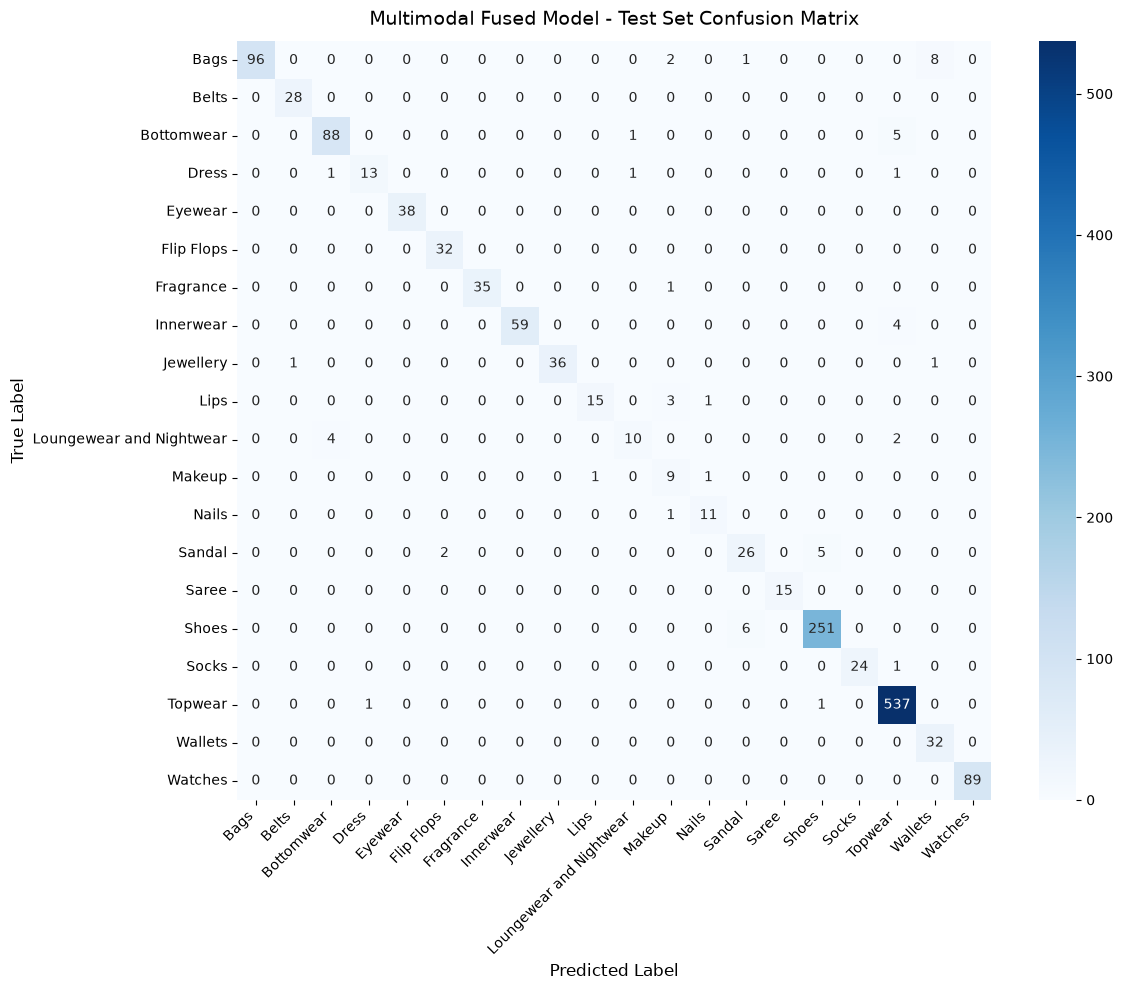

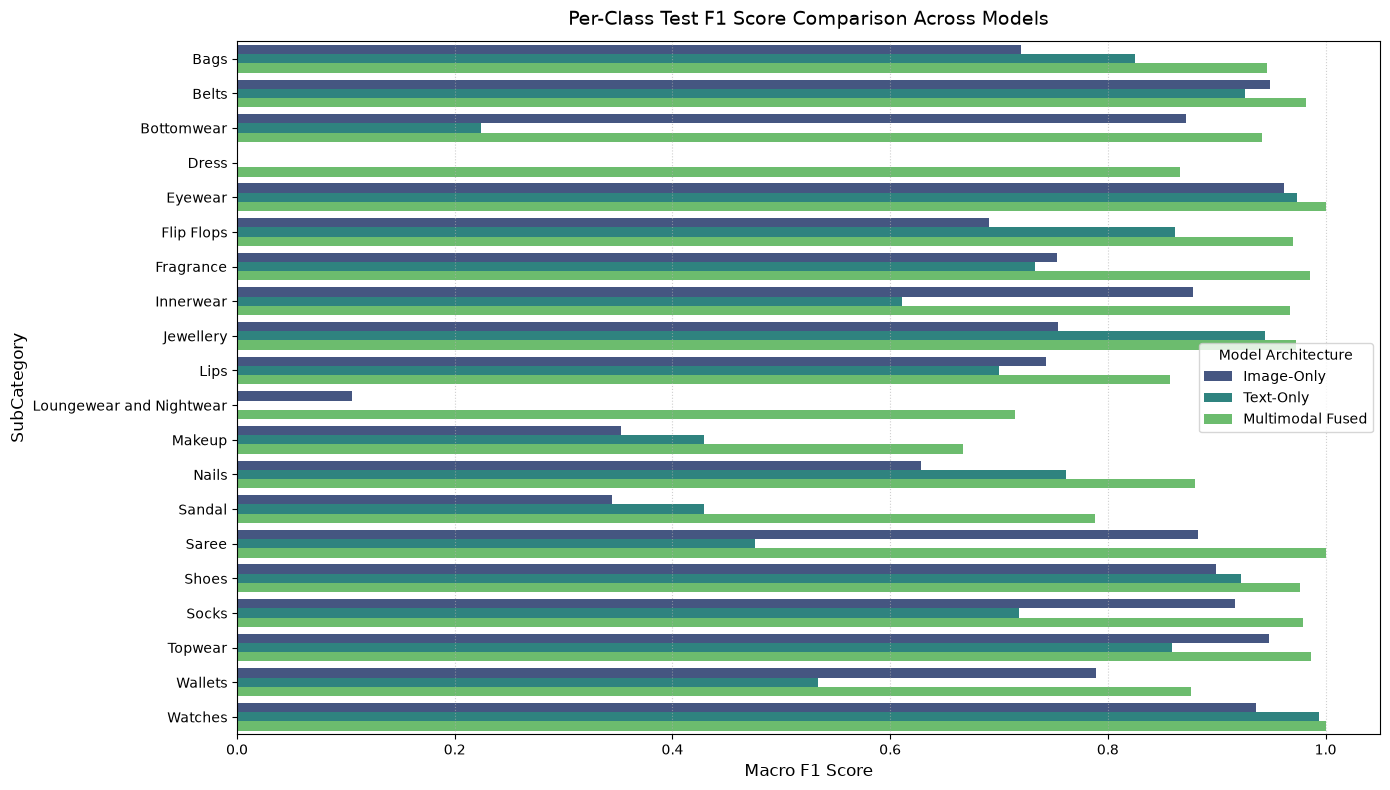

In [35]:
if "test_df" not in locals():
    test_df = pd.read_csv("myntradataset/test_split.csv")

test_mm_dataset = MyntraMultimodalDataset(
    test_df,
    img_transform=val_test_transform,
    tokenizer=tokenizer,
    max_len=MAX_LEN,
    label_map=category_to_idx,
)
test_mm_loader = DataLoader(
    test_mm_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)


def evaluate_model_on_test(model, test_loader, model_type, checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    test_preds, test_targets = [], []

    with torch.no_grad():
        for batch in test_loader:
            if model_type == "image":
                images, labels = batch
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
            elif model_type == "text":
                input_ids = batch["input_ids"].to(device)
                attention_mask = batch["attention_mask"].to(device)
                labels = batch["label"].to(device)
                outputs = model(
                    input_ids=input_ids, attention_mask=attention_mask
                )
            elif model_type == "multimodal":
                images = batch["image"].to(device)
                input_ids = batch["input_ids"].to(device)
                attention_mask = batch["attention_mask"].to(device)
                labels = batch["label"].to(device)
                outputs = model(images, input_ids, attention_mask)

            preds = torch.argmax(outputs, dim=1)
            test_preds.extend(preds.cpu().numpy())
            test_targets.extend(labels.cpu().numpy())

    acc = accuracy_score(test_targets, test_preds)
    macro_f1 = f1_score(
        test_targets, test_preds, average="macro", zero_division=0
    )
    weighted_f1 = f1_score(
        test_targets, test_preds, average="weighted", zero_division=0
    )

    return {
        "accuracy": acc,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "preds": np.array(test_preds),
        "targets": np.array(test_targets),
    }


print("Evaluating best models on shared test set...")

eval_img = evaluate_model_on_test(
    model_image,
    test_loader,
    "image",
    "checkpoints/best_resnet18_image_only.pt",
)
eval_txt = evaluate_model_on_test(
    model_text,
    test_text_loader,
    "text",
    "checkpoints/best_distilbert_text_only.pt",
)
eval_mm = evaluate_model_on_test(
    model_multimodal,
    test_mm_loader,
    "multimodal",
    "checkpoints/best_multimodal_resnet_distilbert.pt",
)

comparison_table = pd.DataFrame(
    [
        {
            "Model Architecture": "ResNet18 Image-Only",
            "Accuracy": f"{eval_img['accuracy']:.4f}",
            "Macro F1": f"{eval_img['macro_f1']:.4f}",
            "Weighted F1": f"{eval_img['weighted_f1']:.4f}",
        },
        {
            "Model Architecture": "DistilBERT Text-Only",
            "Accuracy": f"{eval_txt['accuracy']:.4f}",
            "Macro F1": f"{eval_txt['macro_f1']:.4f}",
            "Weighted F1": f"{eval_txt['weighted_f1']:.4f}",
        },
        {
            "Model Architecture": "Multimodal (Image + Text)",
            "Accuracy": f"{eval_mm['accuracy']:.4f}",
            "Macro F1": f"{eval_mm['macro_f1']:.4f}",
            "Weighted F1": f"{eval_mm['weighted_f1']:.4f}",
        },
    ]
)

print("\n" + "=" * 65)
print("            SHARED TEST SET PERFORMANCE COMPARISON            ")
print("=" * 65)
print(comparison_table.to_string(index=False))


log_files = {
    "ResNet18 Image-Only": "checkpoints/log_resnet18_image_only.json",
    "DistilBERT Text-Only": "checkpoints/log_distilbert_text_only.json",
    "Multimodal Fused": "checkpoints/log_multimodal_resnet_distilbert.json",
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, path in log_files.items():
    if os.path.exists(path):
        with open(path, "r") as f:
            data = json.load(f)
            history = data["history"]
            epochs = [h["epoch"] for h in history]
            train_loss = [h["train_loss"] for h in history]
            val_loss = [h["val_loss"] for h in history]
            val_f1 = [h["val_f1"] for h in history]

            axes[0].plot(
                epochs, val_loss, label=f"{name} (Val)", linestyle="--"
            )
            axes[1].plot(epochs, val_f1, label=name, marker="o")

axes[0].set_title("Validation Loss over Epochs", fontsize=12)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("CrossEntropy Loss")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

axes[1].set_title("Validation Macro F1 over Epochs", fontsize=12)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


class_names = [
    cat for cat, _ in sorted(category_to_idx.items(), key=lambda x: x[1])
]
cm = confusion_matrix(eval_mm["targets"], eval_mm["preds"])

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True,
)
plt.title(
    "Multimodal Fused Model - Test Set Confusion Matrix", fontsize=14, pad=12
)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


f1_per_class_mm = f1_score(
    eval_mm["targets"], eval_mm["preds"], average=None, zero_division=0
)
f1_per_class_img = f1_score(
    eval_img["targets"], eval_img["preds"], average=None, zero_division=0
)
f1_per_class_txt = f1_score(
    eval_txt["targets"], eval_txt["preds"], average=None, zero_division=0
)

df_per_class = pd.DataFrame(
    {
        "SubCategory": class_names,
        "Image-Only": f1_per_class_img,
        "Text-Only": f1_per_class_txt,
        "Multimodal Fused": f1_per_class_mm,
    }
).melt(id_vars="SubCategory", var_name="Model", value_name="F1 Score")

plt.figure(figsize=(14, 8))
sns.barplot(
    data=df_per_class,
    x="F1 Score",
    y="SubCategory",
    hue="Model",
    palette="viridis",
)
plt.title(
    "Per-Class Test F1 Score Comparison Across Models", fontsize=14, pad=12
)
plt.xlabel("Macro F1 Score", fontsize=12)
plt.ylabel("SubCategory", fontsize=12)
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.legend(title="Model Architecture")
plt.tight_layout()
plt.show()

## Show some mistakes by the models

Found 56 total fusion mistakes on the test set.
Displaying 5 actual misclassifications for inspection:



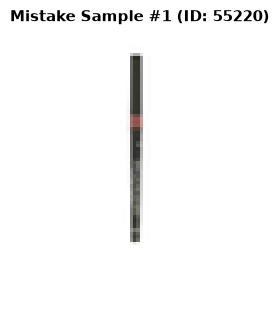

Mistake Sample #1 Breakdown:
  • Input Text          : Product: Lakme Absolute Forever Silk Chestnut Lip Liner 03. Color: Brown. Usage: Casual.
  • True SubCategory    : Lips
  • Image-Only Model    : Lips
  • Text-Only Model     : Lips
  • Multimodal (Fused)  : Makeup

------------------------------------------------------------


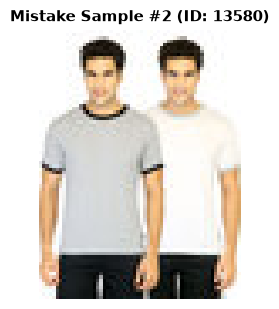

Mistake Sample #2 Breakdown:
  • Input Text          : Product: Hanes Men Pack of 2 Half Contrast Piping Ringer T-shirts. Color: White. Usage: Casual.
  • True SubCategory    : Innerwear
  • Image-Only Model    : Topwear
  • Text-Only Model     : Topwear
  • Multimodal (Fused)  : Topwear

------------------------------------------------------------


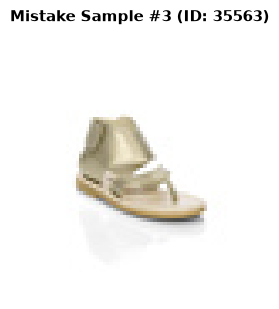

Mistake Sample #3 Breakdown:
  • Input Text          : Product: Enroute Teens Gold Sandals. Color: Gold. Usage: Casual.
  • True SubCategory    : Sandal
  • Image-Only Model    : Shoes
  • Text-Only Model     : Shoes
  • Multimodal (Fused)  : Shoes

------------------------------------------------------------


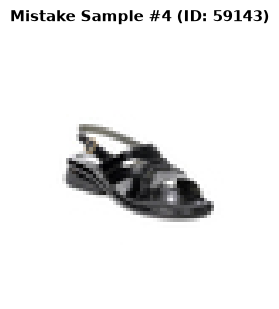

Mistake Sample #4 Breakdown:
  • Input Text          : Product: Tiptopp Women Black Sandals. Color: Black. Usage: Casual.
  • True SubCategory    : Shoes
  • Image-Only Model    : Sandal
  • Text-Only Model     : Shoes
  • Multimodal (Fused)  : Sandal

------------------------------------------------------------


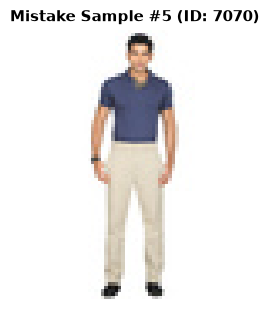

Mistake Sample #5 Breakdown:
  • Input Text          : Product: Timberland Men's Cycling Pod Chino Khaki Pant. Color: Cream. Usage: Casual.
  • True SubCategory    : Bottomwear
  • Image-Only Model    : Loungewear and Nightwear
  • Text-Only Model     : Topwear
  • Multimodal (Fused)  : Loungewear and Nightwear

------------------------------------------------------------


In [37]:
idx_to_cat = {v: k for k, v in category_to_idx.items()}

fusion_mistake_indices = np.where(eval_mm["preds"] != eval_mm["targets"])[0]

NUM_EXAMPLES = 5
selected_indices = fusion_mistake_indices[:NUM_EXAMPLES]

print(
    f"Found {len(fusion_mistake_indices)} total fusion mistakes on the test set."
)
print(f"Displaying {NUM_EXAMPLES} actual misclassifications for inspection:\n")

for rank, idx in enumerate(selected_indices, 1):
    row = test_df.iloc[idx]

    pid = str(row["id"]).split(".")[0].strip()
    if "image_path" in row and pd.notna(row["image_path"]):
        img_path = row["image_path"]
    else:
        img_path = os.path.join("myntradataset/images", f"{pid}.jpg")

    true_label = idx_to_cat[eval_mm["targets"][idx]]
    img_pred = idx_to_cat[eval_img["preds"][idx]]
    txt_pred = idx_to_cat[eval_txt["preds"][idx]]
    mm_pred = idx_to_cat[eval_mm["preds"][idx]]

    name = str(row.get("productDisplayName", "N/A"))
    colour = str(row.get("baseColour", "N/A"))
    usage = str(row.get("usage", "N/A"))
    input_text = f"Product: {name}. Color: {colour}. Usage: {usage}."

    fig, ax = plt.subplots(figsize=(3.5, 3.5))
    if os.path.exists(img_path):
        try:
            img = Image.open(img_path)
            ax.imshow(img)
        except Exception:
            ax.text(
                0.5,
                0.5,
                "Image Corrupt",
                ha="center",
                va="center",
                color="red",
            )
    else:
        ax.text(
            0.5, 0.5, "Image Missing", ha="center", va="center", color="red"
        )

    ax.axis("off")
    ax.set_title(
        f"Mistake Sample #{rank} (ID: {pid})", fontsize=11, fontweight="bold"
    )
    plt.show()

    print(f"Mistake Sample #{rank} Breakdown:")
    print(f"  • Input Text          : {input_text}")
    print(f"  • True SubCategory    : {true_label}")
    print(f"  • Image-Only Model    : {img_pred}")
    print(f"  • Text-Only Model     : {txt_pred}")
    print(f"  • Multimodal (Fused)  : {mm_pred}")
    print("\n" + "-" * 60)